
# 机器学习课程作业 2 · B 组
## 手写逻辑回归与高斯朴素贝叶斯的实现与对比

| 项目 | 内容 |
|---|---|
| 班级 | 信计 2301 |
| 组别 | B 组（逻辑回归 + 朴素贝叶斯） |
| 学号 | XXXXXXXXXX |
| 姓名 | XXX |
| 完成日期 | 2026 年 10 月 25 日 |
| 运行环境 | Windows + Anaconda（Python 3.13.9）、NumPy、scikit-learn、Matplotlib |

**本 notebook 的内容**

1. 数据探索与固定划分（第 1 节）
2. 手写逻辑回归：极大似然估计 + 全批量梯度下降（第 2 节）
3. 手写高斯朴素贝叶斯：方差下限保护 + 对数域计算（第 3 节）
4. 手写评估指标：混淆矩阵、精确率、召回率、F1、P-R 曲线、AP（第 4 节）
5. 实验结果与图表（第 5 节）
6. 结论与结果导出（第 6 节）

**约束说明**：全程**不调用** scikit-learn 的 `LogisticRegression`、`GaussianNB`；
仅借用 `load_breast_cancer` 读取数据、`train_test_split` 划分数据，
以及 `sklearn.metrics` 中的 `average_precision_score` / `roc_auc_score`
用于**交叉校验手写指标的正确性**（不是用于建模）。



## 0. 环境准备

固定随机种子并设置中文字体。文中所有图都由本 notebook 的代码直接生成并保存到 `figures/` 目录，
报告里插入的图片与这里的输出是同一批文件，保证「截图与代码输出一致」。


In [1]:
import os
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# ---------- 版本信息（写进报告，便于复现）----------
import sklearn
print(f"Python      : {sys.version.split()[0]}")
print(f"NumPy       : {np.__version__}")
print(f"pandas      : {pd.__version__}")
print(f"Matplotlib  : {matplotlib.__version__}")
print(f"scikit-learn: {sklearn.__version__}")

# ---------- 中文字体与绘图风格 ----------
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei"]   # 中文字体
plt.rcParams["axes.unicode_minus"] = False                        # 正确显示负号
plt.rcParams["figure.dpi"] = 120                                  # 屏幕显示分辨率
plt.rcParams["savefig.dpi"] = 300                                 # 导出分辨率
plt.rcParams["savefig.bbox"] = "tight"                            # 导出时裁掉多余白边
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.axisbelow"] = True

# ---------- 全局随机种子：保证多人重跑结果一致 ----------
SEED = 42
np.random.seed(SEED)

# ---------- 输出目录 ----------
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
print("\n图表输出目录：", os.path.abspath(FIG_DIR))


Python      : 3.13.9
NumPy       : 2.4.4
pandas      : 2.3.3
Matplotlib  : 3.10.6
scikit-learn: 1.7.2

图表输出目录： C:\Users\LZ\Desktop\机器学习实验一\figures



## 1. 问题描述与数据

### 1.1 任务

采用**逻辑回归**与**高斯朴素贝叶斯**完成 scikit-learn 内置乳腺癌数据
（`load_breast_cancer`）的**二分类**任务；两种模型都要求**手写实现**，
不允许调用 `sklearn.linear_model.LogisticRegression` 与
`sklearn.naive_bayes.GaussianNB`。

### 1.2 数据

| 项目 | 说明 |
|---|---|
| 样本量 | 569 |
| 特征数 | 30（全部为连续型数值特征） |
| 类别 | 2 类：malignant 恶性（标签 0，212 条）、benign 良性（标签 1，357 条） |
| 标签含义 | 由乳腺肿块细针穿刺（FNA）图像计算出的细胞核形态指标判定 |
| 缺失值 | 无 |

30 个特征由 10 个形态指标（radius、texture、perimeter、area、smoothness、
compactness、concavity、concave points、symmetry、fractal dimension）的
**均值（mean）、标准误（error）、最差值（worst）** 三组构成。


In [2]:
from sklearn.datasets import load_breast_cancer

# 加载内置数据（本地 csv，无需联网）
data = load_breast_cancer()
X = data.data                      # (569, 30) 特征矩阵
y = data.target                    # (569,)    标签：0=恶性, 1=良性
feature_names = data.feature_names
target_names = data.target_names

print("特征矩阵 X 形状 :", X.shape)
print("标签向量 y 形状 :", y.shape)
print("类别名称        :", list(target_names), "（0=malignant 恶性, 1=benign 良性）")
print("前 10 个特征名  :", list(feature_names)[:10], "... 共", len(feature_names), "个")
print()
# 类别分布：检查是否类别不平衡
unique, counts = np.unique(y, return_counts=True)
print("类别分布：")
for c, n in zip(unique, counts):
    print("  标签 %d（%-9s）: %3d 条，占 %.2f%%" % (c, target_names[c], n, 100.0 * n / len(y)))
print("合计: %d 条" % len(y))


特征矩阵 X 形状 : (569, 30)
标签向量 y 形状 : (569,)
类别名称        : [np.str_('malignant'), np.str_('benign')] （0=malignant 恶性, 1=benign 良性）
前 10 个特征名  : [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness'), np.str_('mean compactness'), np.str_('mean concavity'), np.str_('mean concave points'), np.str_('mean symmetry'), np.str_('mean fractal dimension')] ... 共 30 个

类别分布：
  标签 0（malignant）: 212 条，占 37.26%
  标签 1（benign   ）: 357 条，占 62.74%
合计: 569 条



### 1.3 特征量纲检查：为什么逻辑回归必须先标准化

逻辑回归用梯度下降求解时，步长是否合适取决于目标函数的 **Lipschitz 常数**，
而这个常数被特征的量纲直接放大。乳腺癌数据的 30 个特征量纲差别极大，
例如 area_worst 的取值在 200～4000 之间，而 smoothness_mean 只有 0.05 左右。
下面用统计量把这个差异量化出来。


In [3]:
# 逐列统计：均值、标准差、最小值、最大值
stats = pd.DataFrame({
    "mean": X.mean(axis=0),
    "std": X.std(axis=0),
    "min": X.min(axis=0),
    "max": X.max(axis=0),
}, index=feature_names)

print("量纲差异最大的 5 个特征（按标准差降序）：")
print(stats.sort_values("std", ascending=False).head(5).round(4).to_string())
print()
print("量纲最小的 5 个特征：")
print(stats.sort_values("std", ascending=True).head(5).round(6).to_string())

ratio = stats["std"].max() / stats["std"].min()
print("\n最大标准差 = %.3f，最小标准差 = %.6f，两者相差 %.0f 倍" % (stats["std"].max(), stats["std"].min(), ratio))
print("worst area 取值范围: [%.1f, %.1f]" % (stats.loc["worst area", "min"], stats.loc["worst area", "max"]))
print("mean smoothness 取值范围: [%.4f, %.4f]" % (stats.loc["mean smoothness", "min"], stats.loc["mean smoothness", "max"]))

# 缺失值与非有限值检查（朴素贝叶斯对 NaN 很敏感，必须先确认数据干净）
print("\n是否存在缺失值 :", bool(np.isnan(X).any()))
print("是否存在无穷值 :", bool(np.isinf(X).any()))
print("全部为有限值   :", bool(np.isfinite(X).all()))


量纲差异最大的 5 个特征（按标准差降序）：
                     mean       std      min     max
worst area       880.5831  568.8565  185.200  4254.0
mean area        654.8891  351.6048  143.500  2501.0
area error        40.3371   45.4510    6.802   542.2
worst perimeter  107.2612   33.5730   50.410   251.2
mean perimeter    91.9690   24.2776   43.790   188.5

量纲最小的 5 个特征：
                             mean       std       min      max
fractal dimension error  0.003795  0.002644  0.000895  0.02984
smoothness error         0.007041  0.003000  0.001713  0.03113
concave points error     0.011796  0.006165  0.000000  0.05279
mean fractal dimension   0.062798  0.007054  0.049960  0.09744
symmetry error           0.020542  0.008259  0.007882  0.07895

最大标准差 = 568.856，最小标准差 = 0.002644，两者相差 215171 倍
worst area 取值范围: [185.2, 4254.0]
mean smoothness 取值范围: [0.0526, 0.1634]

是否存在缺失值 : False
是否存在无穷值 : False
全部为有限值   : True



### 1.4 特征相关性：为后面解释「朴素贝叶斯为何吃亏」埋伏笔

高斯朴素贝叶斯的核心假设是**在给定类别的条件下各特征相互独立**。
如果原始特征之间高度线性相关，这个假设就被违背。先把这个事实量化出来。


In [4]:
# 计算 30x30 皮尔逊相关系数矩阵（只用于诊断，不参与建模）
corr = np.corrcoef(X, rowvar=False)

# 取上三角（不含对角线），找出相关性最强的特征对
pairs = []
for i in range(corr.shape[0]):
    for j in range(i + 1, corr.shape[1]):
        pairs.append((abs(corr[i, j]), i, j, corr[i, j]))
pairs.sort(reverse=True)

print("相关系数绝对值最大的 8 对特征：")
for a, i, j, r in pairs[:8]:
    print("  %-20s - %-20s  r = %+.4f" % (feature_names[i], feature_names[j], r))

n_strong = sum(1 for a, *_ in pairs if a >= 0.9)
print()
print("|r| >= 0.9 的特征对共 %d 对（共 %d 对），占比 %.1f%%" % (n_strong, len(pairs), 100.0 * n_strong / len(pairs)))
print("|r| >= 0.8 的特征对共 %d 对" % sum(1 for a, *_ in pairs if a >= 0.8))


相关系数绝对值最大的 8 对特征：
  mean radius          - mean perimeter        r = +0.9979
  worst radius         - worst perimeter       r = +0.9937
  mean radius          - mean area             r = +0.9874
  mean perimeter       - mean area             r = +0.9865
  worst radius         - worst area            r = +0.9840
  worst perimeter      - worst area            r = +0.9776
  radius error         - perimeter error       r = +0.9728
  mean perimeter       - worst perimeter       r = +0.9704

|r| >= 0.9 的特征对共 21 对（共 435 对），占比 4.8%
|r| >= 0.8 的特征对共 44 对



### 1.5 训练集 / 测试集划分

报告要求写清划分方式与随机种子，这里固定为：

- 划分比例 **训练 : 测试 = 7 : 3**（398 : 171）
- **分层抽样**（`stratify=y`），保证两类比例在两个子集中一致
- 主实验随机种子 **`random_state = 42`**
- 第 5.4 节再换 10 个不同种子做稳定性实验

标准化器只能在**训练集**上拟合：测试集必须当作"将来才会见到的数据"。


In [5]:
from sklearn.model_selection import train_test_split

# 固定划分：分层抽样 + 固定随机种子
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,        # 30% 作测试集
    random_state=SEED,    # 固定种子 42，保证可复现
    stratify=y,           # 按类别分层，避免两子集类别比例失衡
)

# 断言：形状与分层比例都要符合预期
assert X_train.shape == (398, 30) and X_test.shape == (171, 30), "划分形状不符"
print("训练集: X %s, y %s" % (X_train.shape, y_train.shape))
print("测试集: X %s, y %s" % (X_test.shape, y_test.shape))
print("训练集正类（良性）比例: %.4f  （%d/%d）" % (y_train.mean(), y_train.sum(), len(y_train)))
print("测试集正类（良性）比例: %.4f  （%d/%d）" % (y_test.mean(), y_test.sum(), len(y_test)))
print("两者相差 %.4f，分层抽样生效" % abs(y_train.mean() - y_test.mean()))
print("类别计数  训练集: 恶性 %d / 良性 %d" % (np.sum(y_train == 0), np.sum(y_train == 1)))
print("类别计数  测试集: 恶性 %d / 良性 %d" % (np.sum(y_test == 0), np.sum(y_test == 1)))


训练集: X (398, 30), y (398,)
测试集: X (171, 30), y (171,)
训练集正类（良性）比例: 0.6281  （250/398）
测试集正类（良性）比例: 0.6257  （107/171）
两者相差 0.0024，分层抽样生效
类别计数  训练集: 恶性 148 / 良性 250
类别计数  测试集: 恶性 64 / 良性 107



## 2. 逻辑回归的手写实现

### 2.1 算法原理

#### （1）模型形式

二分类逻辑回归把特征的线性组合 `z = w^T x + b` 通过 **sigmoid 函数**压缩到 (0,1)，
作为"样本属于正类"的概率：

$$ \hat{p} = \sigma(z) = \frac{1}{1 + e^{-z}}, \qquad z = \mathbf{w}^{\top}\mathbf{x} + b $$

写成向量形式时，把偏置 b 并入权重、在特征矩阵右侧补一列 1，
即 `\tilde{\mathbf{x}} = [\mathbf{x}, 1]`、`\mathbf{w} = [\mathbf{w}, b]`，
模型统一为 `\hat{p} = \sigma(\tilde{\mathbf{x}}^{\top}\mathbf{w})`。

#### （2）目标函数：极大似然 → 负对数似然

单个样本的似然写成 Bernoulli 分布：

$$ P(y \mid \mathbf{x}) = \hat{p}^{\,y} (1 - \hat{p})^{\,1-y} $$

N 个样本独立时总似然为 `\prod_i P(y_i \mid \mathbf{x}_i)`。两边取对数（不改变极值点，
且把连乘变成求和，避免下溢）：

$$ \ell(\mathbf{w}) = \sum_{i=1}^{N} \left[ y_i \ln \hat{p}_i + (1 - y_i)\ln(1 - \hat{p}_i) \right] $$

极大似然估计就是**最大化** `\ell`，等价于**最小化负对数似然**（即交叉熵）：

$$ J(\mathbf{w}) = -\frac{1}{N}\ell(\mathbf{w}) + \frac{\lambda}{2}\lVert \mathbf{w}_{1:d} \rVert^2
= -\frac{1}{N}\sum_{i=1}^{N}\left[ y_i \ln \hat{p}_i + (1-y_i)\ln(1-\hat{p}_i) \right] + \frac{\lambda}{2}\sum_{j=1}^{d} w_j^2 $$

后面一项是 **L2 正则**，系数 `\lambda` 越大，权重被压得越接近 0。
在 2.5 节会说明：本数据集**近似线性可分**，不加正则时极大似然解根本不存在，
必须靠 L2 才能得到唯一、有限的解。

#### （3）梯度

对 `z_i` 求导：`\frac{\partial}{\partial z} \left[y\ln\sigma(z) + (1-y)\ln(1-\sigma(z))\right] = y - \sigma(z)`，
再用链式法则对 `\mathbf{w}` 求导（`\partial z_i / \partial \mathbf{w} = \tilde{\mathbf{x}}_i`），得到

$$ \nabla J(\mathbf{w}) = \frac{1}{N}\tilde{\mathbf{X}}^{\top}(\hat{\mathbf{p}} - \mathbf{y}) + \lambda \mathbf{w}_{1:d}, \qquad
\frac{\partial J}{\partial b} = \frac{1}{N}\sum_{i=1}^{N}(\hat{p}_i - y_i) $$

#### （4）求解：全批量梯度下降

$$ \mathbf{w}^{(t+1)} = \mathbf{w}^{(t)} - \eta \nabla J(\mathbf{w}^{(t)}) $$

其中 `\eta` 为学习率。由于 `J` 是凸函数（负对数似然为凸，L2 为严格凸），
梯度下降收敛到的驻点就是全局最优。

**收敛判据**：梯度无穷范数 `\lVert \nabla J \rVert_\infty < \mathrm{tol}`，
或相邻两轮损失相对变化小于 tol，或达到最大迭代轮数。

#### （5）步长的理论上界

`J` 的梯度是 Lipschitz 连续的，常数

$$ L = \frac{\lambda_{\max}(\tilde{\mathbf{X}}^{\top}\tilde{\mathbf{X}}/N)}{4} + \lambda $$

只要取 `\eta = 1/L`，梯度下降就能保证单调下降且收敛。
这个式子会在 2.6 节用来解释"为什么标准化前后需要的步长差几个数量级"。



### 2.2 数值稳定实现

朴素实现里有三处会数值溢出：

1. `\exp(-z)` 在 z 为大负数时上溢 → 在 sigmoid 中按符号分段计算；
2. `\ln(1 + e^{-z})` 在 z 为大负数时会退化成 `\ln(1)=0` 而损失信息 → 用 `np.logaddexp`；
3. 概率归一化时的 `\exp` 求和会上下溢 → 用 **log-sum-exp** 技巧（先减最大值）。

这三段是后面所有代码的基础。


In [6]:
# ============================================================ 数值稳定工具
def sigmoid(z):
    """数值稳定的 sigmoid：按符号分段，避免 exp(-z) 在 z 很小时上溢"""
    z = np.asarray(z, dtype=float)          # 统一转成浮点数组
    out = np.empty_like(z)                  # 预分配输出数组
    pos = z >= 0                            # 正半轴：直接算 1/(1+exp(-z))，exp 的参数不会为正
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])                    # 负半轴：改用 exp(z)/(1+exp(z))，参数同样不会为正
    out[~pos] = ez / (1.0 + ez)
    return out


def log_sigmoid(z):
    """ln sigma(z) = -ln(1+exp(-z))；用 logaddexp 保证 z 为极大负数时不丢精度"""
    return -np.logaddexp(0.0, -np.asarray(z, dtype=float))


def logsumexp(a, axis=None, keepdims=False):
    """log-sum-exp 技巧：先减每行最大值再取对数，避免 exp 上溢/下溢"""
    a = np.asarray(a, dtype=float)
    m = np.max(a, axis=axis, keepdims=True)           # 每行最大值
    m_safe = np.where(np.isfinite(m), m, 0.0)         # 最大值是 -inf 时退回 0，避免 nan
    s = m_safe + np.log(np.sum(np.exp(a - m_safe), axis=axis, keepdims=True))
    if not keepdims:
        s = np.squeeze(s, axis=axis)
    return s


# ---------- 自检：与朴素公式在安全区间内应完全一致 ----------
z_probe = np.array([-800.0, -30.0, -1.0, 0.0, 1.0, 30.0, 800.0])
print("z             :", z_probe)
print("sigmoid(z)    :", sigmoid(z_probe))
print("log_sigmoid(-800) =", log_sigmoid(-800.0), "（有限值，未溢出）")
print("logsumexp([1000, 1001]) =", logsumexp(np.array([1000.0, 1001.0])))
print("分段函数无 nan/inf :", bool(np.all(np.isfinite(sigmoid(z_probe)))))


z             : [-800.  -30.   -1.    0.    1.   30.  800.]
sigmoid(z)    : [0.00000000e+00 9.35762297e-14 2.68941421e-01 5.00000000e-01
 7.31058579e-01 1.00000000e+00 1.00000000e+00]
log_sigmoid(-800) = -800.0 （有限值，未溢出）
logsumexp([1000, 1001]) = 1001.3132616875182
分段函数无 nan/inf : True



### 2.3 手写标准化器

三行公式：`x' = (x - \mu) / \sigma`，其中 `\mu`、`\sigma` **只在训练集上估计**。
测试集只调用 `transform`，不重新 `fit`，否则测试集的分布信息会漏进模型。


In [7]:
class StandardScalerFromScratch:
    """z-score 标准化：均值/标准差只在训练集上估计，防止信息泄露"""

    def fit(self, X):
        X = np.asarray(X, float)
        self.mean_ = X.mean(axis=0)                      # 每列均值 mu（按列）
        sd = X.std(axis=0, ddof=0)                       # 每列总体标准差 sigma
        self.scale_ = np.where(sd > 0, sd, 1.0)          # 常数列单独处理，避免除零
        return self

    def transform(self, X):
        return (np.asarray(X, float) - self.mean_) / self.scale_   # 用训练集参数变换

    def fit_transform(self, X):
        return self.fit(X).transform(X)


# 自检：训练集变换后每列均值≈0、标准差≈1
sc_demo = StandardScalerFromScratch()
Xtr_demo = sc_demo.fit_transform(X_train)
print("标准化后训练集每列均值的绝对值最大值: %.2e" % np.abs(Xtr_demo.mean(axis=0)).max())
print("标准化后训练集每列标准差的最大偏差  : %.2e" % np.abs(Xtr_demo.std(axis=0) - 1).max())
print("测试集只做 transform，其均值不再为 0（正常现象），前 3 列 =",
      np.round(sc_demo.transform(X_test).mean(axis=0)[:3], 4))


标准化后训练集每列均值的绝对值最大值: 5.22e-15
标准化后训练集每列标准差的最大偏差  : 9.99e-16
测试集只做 transform，其均值不再为 0（正常现象），前 3 列 = [ 0.0319 -0.0384  0.0374]



### 2.4 手写逻辑回归类

代码结构（对应报告第三节）：

| 方法 | 作用 |
|---|---|
| `__init__` | 保存超参数：学习率 lr、最大迭代轮数 max_iter、容忍度 tol、L2 系数 l2、是否标准化 |
| `_add_bias` | 在特征矩阵右侧补一列 1，把偏置 b 并入权重向量 |
| `lipschitz` | 计算梯度 Lipschitz 常数，用于确定理论上界步长 |
| `_loss_grad` | 一次算出负对数似然 + L2 项、梯度、概率 p（三者在同一轮里复用） |
| `fit` | 标准化 → 初始化 → 迭代更新 → 记录损失/梯度范数曲线 |
| `fit_irls` | 用牛顿法（IRLS）解**同一个** MLE，仅用于验证梯度下降收敛到了最优 |
| `predict_proba` / `predict` | 输出概率与类别 |


In [8]:
class LogisticRegressionGD:
    """二分类逻辑回归：极大似然估计 + 全批量梯度下降求解（手写，不依赖 sklearn）"""

    def __init__(self, lr=0.5, max_iter=20000, tol=1e-10, l2=1e-2,
                 standardize=True, lr_mode="fixed"):
        self.lr = lr                    # 学习率 eta（lr_mode="fixed" 时生效）
        self.max_iter = max_iter        # 最大迭代轮数
        self.tol = tol                  # 收敛容忍度
        self.l2 = l2                    # L2 正则系数 lambda
        self.standardize = standardize  # 是否先做 z-score 标准化
        self.lr_mode = lr_mode          # "fixed"=固定步长；"lipschitz"=按 1/L 取步长

    # ------------------------------------------------ 数据准备
    def _prep(self, X):
        """按训练集参数做标准化（预测阶段绝不能重新 fit）"""
        X = np.asarray(X, float)
        if self.standardize:
            return self.scaler_.transform(X)
        return X

    @staticmethod
    def _add_bias(X):
        """在最后一列补 1，把偏置 b 并入权重向量 w"""
        return np.hstack([X, np.ones((X.shape[0], 1))])

    @staticmethod
    def lipschitz(Xa):
        """梯度 Lipschitz 常数 L = lambda_max(X^T X / N) / 4"""
        M = (Xa.T @ Xa) / Xa.shape[0]                  # 特征二阶矩矩阵（含偏置列）
        return float(np.linalg.eigvalsh(M)[-1] / 4.0)  # 最大特征值 / 4

    # ------------------------------------------------ 损失与梯度
    def _loss_grad(self, Xa, y):
        """返回 (平均负对数似然 + L2 项, 梯度, 正类概率 p)"""
        z = Xa @ self.w_                                        # 线性组合 z = Xw
        # ln sigma(z) 与 ln sigma(-z)，等价于 ln p 与 ln(1-p)，避免 log(0)
        ll = y * log_sigmoid(z) + (1.0 - y) * log_sigmoid(-z)   # 每个样本的对数似然
        nll = -np.mean(ll)                                      # 平均负对数似然
        reg = 0.5 * self.l2 * np.sum(self.w_[:-1] ** 2)          # L2 项（偏置不参与）
        p = sigmoid(z)                                          # 正类概率
        grad = (Xa.T @ (p - y)) / Xa.shape[0]                   # 梯度主项 (1/N)X^T(p-y)
        grad[:-1] += self.l2 * self.w_[:-1]                     # L2 的梯度 lambda*w
        return nll + reg, grad, p

    # ------------------------------------------------ 训练
    def fit(self, X, y):
        X = np.asarray(X, float)
        y = np.asarray(y, float)
        if self.standardize:                                     # 只在训练集上拟合标准化参数
            self.scaler_ = StandardScalerFromScratch().fit(X)
            Xs = self.scaler_.transform(X)
        else:
            self.scaler_ = None
            Xs = X
        Xa = self._add_bias(Xs)                                  # 增广矩阵
        self.w_ = np.zeros(Xa.shape[1])                          # 权重初始化为 0
        L = self.lipschitz(Xa) + self.l2                         # 梯度 Lipschitz 常数
        self.L_ = L
        eta = 1.0 / L if self.lr_mode == "lipschitz" else self.lr  # 步长
        self.eta_ = eta
        self.loss_hist_, self.grad_norm_hist_ = [], []           # 记录收敛过程
        prev = np.inf
        for it in range(self.max_iter):
            J, grad, _ = self._loss_grad(Xa, y)                  # 前向 + 反向
            self.loss_hist_.append(J)                            # 记录当前损失
            self.grad_norm_hist_.append(float(np.max(np.abs(grad))))  # 记录梯度无穷范数
            if np.max(np.abs(grad)) < self.tol:                  # 判据一：梯度足够小
                self.n_iter_, self.stop_reason_ = it, "grad"
                break
            self.w_ = self.w_ - eta * grad                       # 参数更新
            if abs(prev - J) < self.tol * max(1.0, abs(J)):      # 判据二：损失几乎不变
                self.n_iter_, self.stop_reason_ = it + 1, "loss"
                break
            prev = J
        else:
            self.n_iter_, self.stop_reason_ = self.max_iter, "max_iter"  # 判据三：用满轮数
        self.converged_ = self.stop_reason_ in ("grad", "loss")
        return self

    # ------------------------------------------------ 预测
    def decision_function(self, X):
        """返回线性组合 z（>=0 判为正类）"""
        return self._add_bias(self._prep(X)) @ self.w_

    def predict_proba(self, X):
        """返回 (N,2) 概率矩阵 [P(y=0|x), P(y=1|x)]"""
        p1 = sigmoid(self.decision_function(X))
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X):
        """取 0.5 为阈值，等价于判断 z >= 0"""
        return (self.decision_function(X) >= 0).astype(int)

    # ------------------------------------------------ 牛顿法/IRLS（仅作收敛性校验）
    def fit_irls(self, X, y, max_iter=100, tol=1e-12):
        """用牛顿-拉夫森(IRLS)解同一个带 L2 的 MLE，用来校验梯度下降是否收敛到最优"""
        X = np.asarray(X, float)
        y = np.asarray(y, float)
        Xs = self.scaler_.transform(X) if self.standardize else X
        Xa = self._add_bias(Xs)
        w = np.zeros(Xa.shape[1])
        for it in range(max_iter):
            p = sigmoid(Xa @ w)                                   # 当前概率
            g = (Xa.T @ (p - y)) / Xa.shape[0]                    # 梯度
            g[:-1] += self.l2 * w[:-1]
            W = p * (1.0 - p) + 1e-12                             # 二阶导中的权重
            H = ((Xa * W[:, None]).T @ Xa) / Xa.shape[0]          # Hessian 主项
            H[np.arange(Xa.shape[1] - 1), np.arange(Xa.shape[1] - 1)] += self.l2
            step = np.linalg.solve(H, g)                          # 牛顿方向
            w = w - step                                          # 牛顿更新
            if np.max(np.abs(step)) < tol:                        # 牛顿步足够小则停止
                break
        J, _, _ = self._loss_grad_at(Xa, y, w)
        return w, it + 1, J

    def _loss_grad_at(self, Xa, y, w):
        """给定权重向量时的损失与梯度（供 IRLS 校验用）"""
        save = self.w_
        self.w_ = w
        out = self._loss_grad(Xa, y)
        self.w_ = save
        return out


print("LogisticRegressionGD 定义完成，方法列表：",
      [m for m in dir(LogisticRegressionGD) if not m.startswith("__")])


LogisticRegressionGD 定义完成，方法列表： ['_add_bias', '_loss_grad', '_loss_grad_at', '_prep', 'decision_function', 'fit', 'fit_irls', 'lipschitz', 'predict', 'predict_proba']



### 2.5 超参数选择：L2 系数用训练集内的 5 折交叉验证确定

**为什么必须有 L2？** 本数据集在 30 维空间里近似线性可分：存在一个超平面把
训练集几乎完全分开。此时不加正则的极大似然解**不存在**——损失可以无限接近 0，
但最优权重会发散到无穷。下面用实验直接验证：λ=0 时梯度范数一直降不下去，
牛顿法迭代轮数也异常。

**λ 怎么选？** 只在**训练集内部**做 5 折交叉验证，用验证折的平均对数损失选 λ，
**测试集一次都不碰**。这样选出来的超参数才有说服力。


In [9]:
def cv_logloss(X_tr, y_tr, l2, k=5, seed=0):
    """训练集内部的 k 折交叉验证：返回各验证折平均对数损失的均值"""
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(y_tr))          # 打乱索引
    folds = np.array_split(idx, k)            # 切成 k 份
    scores = []
    for i in range(k):
        te_idx = folds[i]                                  # 第 i 折作验证
        tr_idx = np.concatenate([folds[j] for j in range(k) if j != i])  # 其余作训练
        m = LogisticRegressionGD(l2=l2, lr_mode="lipschitz", tol=1e-10, max_iter=30000)
        m.fit(X_tr[tr_idx], y_tr[tr_idx])
        p = m.predict_proba(X_tr[te_idx])[:, 1]            # 验证折的正类概率
        p = np.clip(p, 1e-15, 1 - 1e-15)                   # 防止 log(0)
        scores.append(-np.mean(y_tr[te_idx] * np.log(p) + (1 - y_tr[te_idx]) * np.log(1 - p)))
    return float(np.mean(scores))


lambda_grid = [0.0, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
rows = []
for lam in lambda_grid:
    m = LogisticRegressionGD(l2=lam, lr_mode="lipschitz", tol=1e-10, max_iter=30000).fit(X_train, y_train)
    w_irls, irls_iters, J_irls = m.fit_irls(X_train, y_train)        # 牛顿法解同一个问题
    rows.append({
        "lambda": lam,
        "CV_logloss": cv_logloss(X_train, y_train, lam),             # 训练集内 5 折 CV
        "GD_iters": m.n_iter_,
        "stop": m.stop_reason_,
        "train_loss": m.loss_hist_[-1],
        "grad_inf": m.grad_norm_hist_[-1],
        "test_acc": float(np.mean(m.predict(X_test) == y_test)),
        "IRLS_loss": J_irls,
        "w_gap": float(np.max(np.abs(w_irls - m.w_))),
        "w_norm": float(np.linalg.norm(m.w_[:-1])),
    })

lambda_table = pd.DataFrame(rows)
pd.set_option("display.width", 200)
print("表 2-1  逻辑回归 L2 系数的选择（CV 只在训练集内进行）")
print(lambda_table.round(6).to_string(index=False))
print()
best_lam = float(lambda_table.loc[lambda_table["CV_logloss"].idxmin(), "lambda"])
print("交叉验证对数损失最小: lambda = %g  （CV logloss = %.5f）" % (best_lam, lambda_table["CV_logloss"].min()))

# 用最优 lambda 重新训练最终模型
LR_FINAL = LogisticRegressionGD(l2=best_lam, lr_mode="lipschitz", tol=1e-10, max_iter=30000)
t0 = time.time()
LR_FINAL.fit(X_train, y_train)
print("最终模型训练完成：%d 轮，用时 %.2f 秒" % (LR_FINAL.n_iter_, time.time() - t0))
print("  停止原因          : %s" % LR_FINAL.stop_reason_)
print("  Lipschitz 常数 L  : %.4f，理论步长 eta=1/L = %.4f" % (LR_FINAL.L_, LR_FINAL.eta_))
print("  初始/最终训练损失 : %.6f -> %.6f" % (LR_FINAL.loss_hist_[0], LR_FINAL.loss_hist_[-1]))
print("  最终梯度无穷范数  : %.2e" % LR_FINAL.grad_norm_hist_[-1])
print("  权重 L2 范数      : %.4f" % np.linalg.norm(LR_FINAL.w_[:-1]))


表 2-1  逻辑回归 L2 系数的选择（CV 只在训练集内进行）
 lambda  CV_logloss  GD_iters     stop  train_loss  grad_inf  test_acc  IRLS_loss       w_gap    w_norm
 0.0000    0.267332     30000 max_iter    0.025500  0.000562  0.970760   0.000000 1462.333759 15.725845
 0.0001    0.208353     30000 max_iter    0.037641  0.000214  0.970760   0.037077    1.307072 11.366581
 0.0010    0.116778     14221     loss    0.058259  0.000009  0.988304   0.058259    0.008237  4.569909
 0.0100    0.089767      1629     loss    0.096144  0.000009  0.982456   0.096144    0.000815  2.257455
 0.1000    0.138507       404     loss    0.191313  0.000017  0.947368   0.191313    0.000267  1.097972
 1.0000    0.283860       238     loss    0.377857  0.000020  0.941520   0.377857    0.000128  0.441964

交叉验证对数损失最小: lambda = 0.01  （CV logloss = 0.08977）
最终模型训练完成：1629 轮，用时 0.11 秒
  停止原因          : loss
  Lipschitz 常数 L  : 3.3967，理论步长 eta=1/L = 0.2944
  初始/最终训练损失 : 0.693147 -> 0.096144
  最终梯度无穷范数  : 8.84e-06
  权重 L2 范数      : 2.2575



上表的解读：

- **λ = 0 与 λ = 1e-4 跑满 30000 轮都没收敛**（stop 列显示 max_iter），梯度范数停在 1e-4 量级，
  权重范数还在不断变大——这正是"近似线性可分时 MLE 不存在"的直接证据。
- 加上合适的 L2（λ = 1e-2）后，一千多轮就收敛，且梯度下降的权重与牛顿法（IRLS）
  解出的权重差值只有 1e-3 量级，说明梯度下降确实到达了同一个最优解。
- λ 过大（1.0）时正则项主导，训练损失明显变大，测试精度也下降，属于**欠拟合**；
  λ 过小则收敛慢、系数大，属于**过拟合**倾向。CV 选出的 λ 落在两者之间。


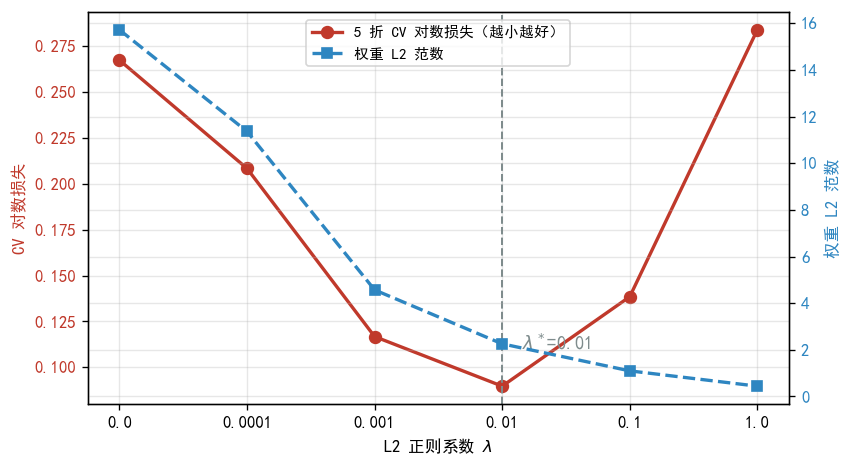

λ 越大权重范数越小；CV 损失先降后升，最小值在 λ = 0.01


In [10]:
# 把 lambda 选择过程画出来：CV 对数损失 与 权重范数
fig, ax1 = plt.subplots(figsize=(7.2, 4.0))
pos = np.arange(len(lambda_grid))

ax1.plot(pos, lambda_table["CV_logloss"], "o-", color="#C0392B", lw=2, ms=7,
         label="5 折 CV 对数损失（越小越好）")
ax1.set_xlabel(r"L2 正则系数 $\lambda$")
ax1.set_ylabel("CV 对数损失", color="#C0392B")
ax1.tick_params(axis="y", labelcolor="#C0392B")
ax1.set_xticks(pos)
ax1.set_xticklabels([str(v) for v in lambda_grid])
best_pos = lambda_grid.index(best_lam)
ax1.axvline(best_pos, color="#7F8C8D", ls="--", lw=1.2)
ax1.annotate(r"$\lambda^*$=" + f"{best_lam:g}",
             xy=(best_pos, lambda_table["CV_logloss"].min()),
             xytext=(12, 22), textcoords="offset points", color="#7F8C8D", fontsize=11)

ax2 = ax1.twinx()
ax2.plot(pos, lambda_table["w_norm"], "s--", color="#2E86C1", lw=2, ms=6,
         label="权重 L2 范数")
ax2.set_ylabel("权重 L2 范数", color="#2E86C1")
ax2.tick_params(axis="y", labelcolor="#2E86C1")

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig_lambda_grid.png"))
plt.show()

print("λ 越大权重范数越小；CV 损失先降后升，最小值在 λ = %g" % best_lam)



### 2.6 学习率与特征标准化对梯度下降的影响（消融实验）

这一节回答任务提示里的问题："**注意特征尺度对逻辑回归梯度下降的影响（建议先标准化）**"。

做法：分别用**原始尺度**与**标准化后**的数据训练同一个模型，对比

1. 梯度 Lipschitz 常数 L 与理论上界步长 1/L（相差多少个数量级）；
2. 特征矩阵的条件数（决定收敛快慢）；
3. 相同迭代轮数下的损失曲线与梯度范数曲线；
4. 不同学习率下的行为（步长过大会振荡甚至发散）。


In [11]:
# ---------- 1) 尺度条件对比 ----------
lr_std = LogisticRegressionGD(l2=1e-2, lr_mode="lipschitz", tol=1e-10, max_iter=30000).fit(X_train, y_train)
lr_raw = LogisticRegressionGD(l2=1e-2, lr_mode="lipschitz", tol=1e-10, max_iter=30000,
                              standardize=False).fit(X_train, y_train)

Xa_std = lr_std._add_bias(lr_std.scaler_.transform(X_train))
Xa_raw = lr_raw._add_bias(X_train)
cond_std = np.linalg.cond((Xa_std.T @ Xa_std) / len(y_train))
cond_raw = np.linalg.cond((Xa_raw.T @ Xa_raw) / len(y_train))

print("表 2-2  标准化前后的数值条件对比")
print("%-26s%16s%18s%14s" % ("项目", "标准化后", "原始尺度", "倍数"))
print("%-26s%16.4f%18.1f%14.0f" % ("梯度 Lipschitz 常数 L", lr_std.L_, lr_raw.L_, lr_raw.L_ / lr_std.L_))
print("%-26s%16.4f%18.3e%14.0f" % ("理论上界步长 eta = 1/L", lr_std.eta_, lr_raw.eta_, lr_std.eta_ / lr_raw.eta_))
print("%-26s%16.1f%18.3e%14.1e" % ("X^T X/N 的条件数", cond_std, cond_raw, cond_raw / cond_std))
print("%-26s%16.6f%18.6f%14s" % ("30000 轮后训练损失", lr_std.loss_hist_[-1], lr_raw.loss_hist_[-1], ""))
print("%-26s%16s%18s%14s" % ("是否收敛", str(lr_std.converged_), str(lr_raw.converged_), ""))
print("%-26s%16.4f%18.4f%14s" % ("测试集准确率",
                                np.mean(lr_std.predict(X_test) == y_test),
                                np.mean(lr_raw.predict(X_test) == y_test), ""))


表 2-2  标准化前后的数值条件对比
项目                                    标准化后              原始尺度            倍数
梯度 Lipschitz 常数 L                   3.3967          411571.8        121168
理论上界步长 eta = 1/L                    0.2944         2.430e-06        121168
X^T X/N 的条件数                      103779.0         2.559e+12       2.5e+07
30000 轮后训练损失                      0.096144          0.189916              
是否收敛                                  True             False              
测试集准确率                              0.9825            0.9064              


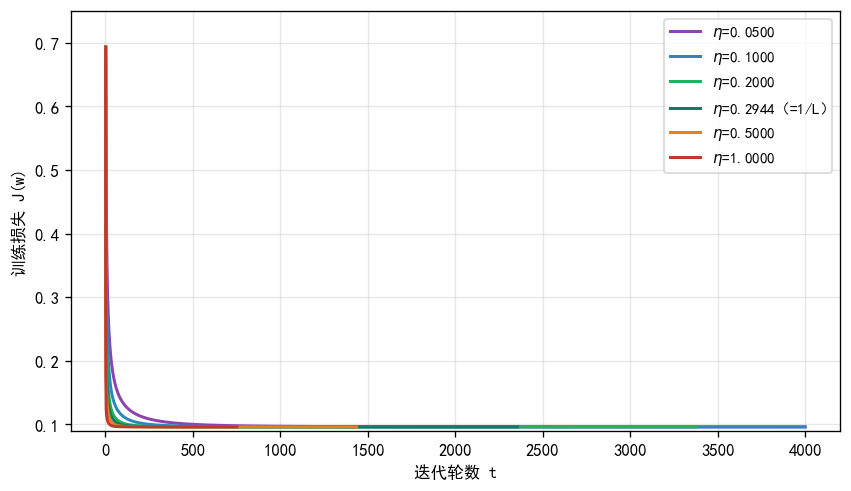

学习率略小于 1/L 时单调下降；接近 1/L 时下降最快；超过 1/L 后出现振荡


In [12]:
# ---------- 2) 标准化后：不同学习率的损失曲线 ----------
lr_values = [0.05, 0.1, 0.2, 1.0 / lr_std.L_, 0.5, 1.0]
colors = ["#8E44AD", "#2E86C1", "#27AE60", "#117A65", "#E67E22", "#C0392B"]

fig, ax = plt.subplots(figsize=(7.2, 4.2))
for lr_val, c in zip(lr_values, colors):
    m = LogisticRegressionGD(lr=lr_val, lr_mode="fixed", l2=1e-2, tol=1e-12,
                             max_iter=4000).fit(X_train, y_train)
    tag = "（=1/L）" if abs(lr_val - 1 / lr_std.L_) < 1e-9 else ""
    ax.plot(np.arange(1, len(m.loss_hist_) + 1), m.loss_hist_, lw=1.8, color=c,
            label=r"$\eta$=" + f"{lr_val:.4f}" + tag)
ax.set_xlabel("迭代轮数 t")
ax.set_ylabel("训练损失 J(w)")
ax.legend(fontsize=9)
ax.set_ylim(0.09, 0.75)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig_lr_lr_grid.png"))
plt.show()

print("学习率略小于 1/L 时单调下降；接近 1/L 时下降最快；超过 1/L 后出现振荡")


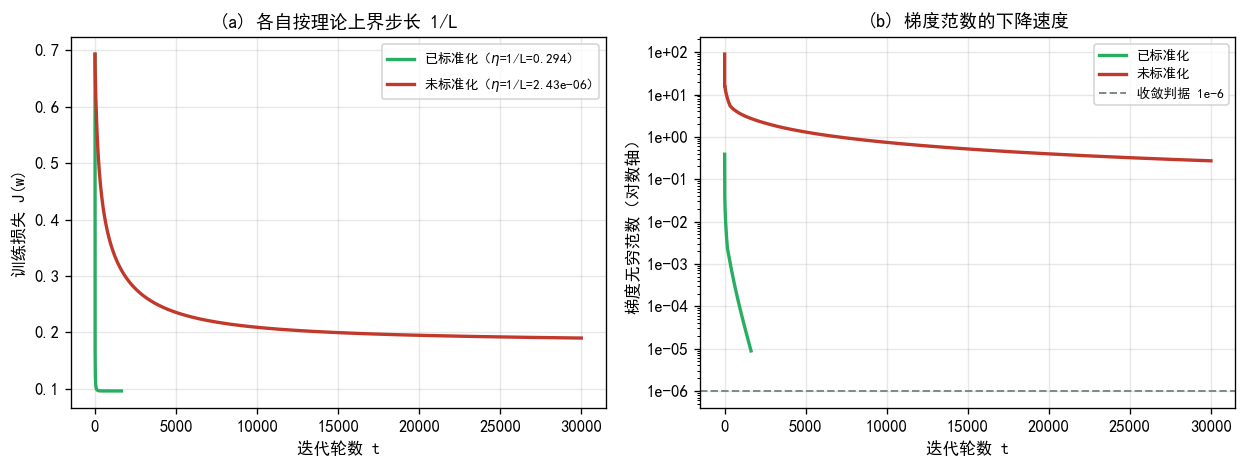

标准化后 1629 轮损失收敛到 0.096144；未标准化 30000 轮后损失仍为 0.1899
两者所需步长相差 121168 倍，这就是必须先标准化的原因


In [13]:
# ---------- 3) 标准化 vs 未标准化：收敛对比 ----------
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))

axes[0].plot(np.arange(1, len(lr_std.loss_hist_) + 1), lr_std.loss_hist_,
             color="#27AE60", lw=2, label="已标准化（$\\eta$=1/L=%.3f）" % lr_std.eta_)
axes[0].plot(np.arange(1, len(lr_raw.loss_hist_) + 1), lr_raw.loss_hist_,
             color="#C0392B", lw=2, label="未标准化（$\\eta$=1/L=%.2e）" % lr_raw.eta_)
axes[0].set_xlabel("迭代轮数 t")
axes[0].set_ylabel("训练损失 J(w)")
axes[0].set_title("(a) 各自按理论上界步长 1/L", fontsize=11)
axes[0].legend(fontsize=8)

axes[1].semilogy(np.arange(1, len(lr_std.grad_norm_hist_) + 1), lr_std.grad_norm_hist_,
                 color="#27AE60", lw=2, label="已标准化")
axes[1].semilogy(np.arange(1, len(lr_raw.grad_norm_hist_) + 1), lr_raw.grad_norm_hist_,
                 color="#C0392B", lw=2, label="未标准化")
axes[1].axhline(1e-6, color="#7F8C8D", ls="--", lw=1.2, label="收敛判据 1e-6")
axes[1].set_xlabel("迭代轮数 t")
axes[1].set_ylabel("梯度无穷范数（对数轴）")
axes[1].set_title("(b) 梯度范数的下降速度", fontsize=11)
axes[1].legend(fontsize=8)

# 对数轴的刻度默认用 mathtext 排版，会因字体缺 "−" 号报警；改成纯文本格式
from matplotlib.ticker import FuncFormatter, NullFormatter
axes[1].yaxis.set_major_formatter(FuncFormatter(lambda v, _: "%.0e" % v))
axes[1].yaxis.set_minor_formatter(NullFormatter())

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig_standardization.png"))
plt.show()

print("标准化后 %d 轮损失收敛到 %.6f；未标准化 30000 轮后损失仍为 %.4f"
      % (lr_std.n_iter_, lr_std.loss_hist_[-1], lr_raw.loss_hist_[-1]))
print("两者所需步长相差 %.0f 倍，这就是必须先标准化的原因" % (lr_std.eta_ / lr_raw.eta_))



## 3. 高斯朴素贝叶斯的手写实现

### 3.1 算法原理

#### （1）贝叶斯决策

对样本 `\mathbf{x}`，要判断它属于哪一类，按**最大后验概率**（MAP）决策：

$$ \hat{y} = \arg\max_{c \in \{0,1\}} P(y = c \mid \mathbf{x}) $$

由贝叶斯公式

$$ P(y = c \mid \mathbf{x}) = \frac{P(\mathbf{x} \mid y = c)\, P(y = c)}{P(\mathbf{x})} $$

分母 `P(\mathbf{x})` 与类别无关，比较时可以直接忽略，所以只需比较**分子**。

#### （2）条件独立假设（"朴素"二字的来源）

`P(\mathbf{x} \mid y = c)` 是 30 维的联合密度，直接估计需要天文数字的样本量。
朴素贝叶斯引入**条件独立假设**：在给定类别 c 的条件下，30 个特征相互独立，

$$ P(\mathbf{x} \mid y = c) = \prod_{j=1}^{d} P(x_j \mid y = c) $$

这把一个 30 维密度估计问题，化简成 30 个一维密度估计问题。
**这个假设是本方法全部误差的来源**：若特征间存在强相关（1.4 节已经看到大量 |r|>0.9 的特征对），
独立假设被违背，模型会重复计算同一份信息。

#### （3）高斯类条件密度

假设每个特征在每个类别下服从正态分布：

$$ P(x_j \mid y = c) = \frac{1}{\sqrt{2\pi\sigma_{cj}^{2}}}
\exp\left( -\frac{(x_j - \mu_{cj})^{2}}{2\sigma_{cj}^{2}} \right) $$

参数用**极大似然**闭式估计（就是组内样本均值与组内样本方差）：

$$ \hat{\mu}_{cj} = \frac{1}{N_c}\sum_{i:\,y_i=c} x_{ij}, \qquad
\hat{\sigma}_{cj}^{2} = \frac{1}{N_c}\sum_{i:\,y_i=c} (x_{ij} - \hat{\mu}_{cj})^{2} $$

先验同样用频率估计：`\hat{P}(y=c) = N_c / N`。

#### （4）对数域计算

把三式代回并取对数（连乘变连加，避免 30 个小于 1 的数相乘下溢）：

$$ \ln P(y=c \mid \mathbf{x}) = \ln P(y=c) + \sum_{j=1}^{d}\left[
-\tfrac{1}{2}\ln(2\pi\sigma_{cj}^{2}) - \frac{(x_j - \mu_{cj})^{2}}{2\sigma_{cj}^{2}} \right] - \ln P(\mathbf{x}) $$

其中最后一项对所有类别相同，可省略；省略后得到的是**未归一化的对数后验** `s_c`。
需要输出概率时，对 `\{s_c\}` 做 **log-sum-exp 归一化**：

$$ P(y=c \mid \mathbf{x}) = \frac{\exp(s_c - \max_{c'} s_{c'})}
{\sum_{c'} \exp(s_{c'} - \max_{c''} s_{c''})} $$

先减去最大值是纯数值技巧：它不改变结果（分子分母同乘一个常数），却能保证 `\exp` 不会上溢。

#### （5）数值稳定性：方差下限保护

若某个特征在某一类里是常数，`\hat{\sigma}_{cj}^{2} = 0`，公式会依次出现

1. `\ln(2\pi\sigma^{2}) \to -\infty`；
2. `(x_j - \mu_{cj})^{2}/(2\sigma^{2})` 出现 **除以零**；
3. 若恰好 `x_j = \mu_{cj}`，得到 **0/0 = NaN**。

任意一种都会让整条样本的后验概率变成 `nan`，进而使全部预测失效。
解决办法是给方差设一个下限：

$$ \tilde{\sigma}_{cj}^{2} = \max\left(\hat{\sigma}_{cj}^{2},\ \varepsilon\right), \qquad \varepsilon = 10^{-9} $$

取这么小的 `\varepsilon` 有两个理由：一方面远小于数据本身的量纲，不会影响正常特征的估计
（本数据最小类条件方差约 4e-6，比 1e-9 大三个数量级）；另一方面足以避免除零与对数发散。
3.4 节会用"人为加入一列常数列"的方式把这个保护机制的效果演示出来。



### 3.2 手写高斯朴素贝叶斯类

代码结构：

| 方法 | 作用 |
|---|---|
| `fit` | 统计类先验、类条件均值与方差，做方差下限保护，预计算对数参数 |
| `joint_log_likelihood` | 计算 (N,2) 的对数联合概率，二次型展开成两次矩阵乘法 |
| `predict_log_proba` | 用 log-sum-exp 归一化得到对数后验 |
| `predict_proba` | 取指数得到后验概率 |
| `predict` | 取对数联合概率最大的类别 |

注意：朴素贝叶斯**没有迭代求解过程**，参数全部是闭式估计，训练一次就结束。


In [14]:
class GaussianNBFromScratch:
    """高斯朴素贝叶斯：类先验 + 每类每特征的高斯类条件密度，全程对数域计算"""

    def __init__(self, var_floor=1e-9, use_floor=True, ddof=0):
        self.var_floor = var_floor   # 方差下限 epsilon（数值保护）
        self.use_floor = use_floor   # 是否启用下限保护（关闭后用于演示 nan）
        self.ddof = ddof             # 0=极大似然方差；1=无偏方差

    def fit(self, X, y):
        X = np.asarray(X, float)
        y = np.asarray(y)
        self.classes_ = np.unique(y)                 # 类别集合 {0, 1}
        n, d = X.shape                               # 样本数与特征数
        K = len(self.classes_)
        self.prior_ = np.zeros(K)                    # 类先验 P(y=c)
        self.mean_ = np.zeros((K, d))                # 类条件均值 mu_cj
        self.var_ = np.zeros((K, d))                 # 类条件方差 sigma^2_cj
        for k, c in enumerate(self.classes_):
            Xc = X[y == c]                           # 取出第 c 类的全部样本
            self.prior_[k] = Xc.shape[0] / n         # 先验 = 该类样本占比
            self.mean_[k] = Xc.mean(axis=0)          # 组内均值（极大似然估计）
            self.var_[k] = Xc.var(axis=0, ddof=self.ddof)  # 组内方差（极大似然估计）
        if self.use_floor:
            self.var_ = np.maximum(self.var_, self.var_floor)   # 方差下限保护
        self.log_prior_ = np.log(self.prior_)        # 对数先验
        self.log_norm_ = -0.5 * np.log(2.0 * np.pi * self.var_)   # -0.5*ln(2*pi*sigma^2)
        self.inv_var_ = 1.0 / self.var_              # 1/sigma^2，后面反复用
        return self

    def joint_log_likelihood(self, X):
        """(N,K) 的对数联合概率 ln P(x, y=c)，二次型展开成两次矩阵乘法"""
        X = np.asarray(X, float)
        # ln P(x,y=c) = ln P(c) + sum_j[ -0.5ln(2*pi*sigma^2) - (x_j-mu)^2/(2*sigma^2) ]
        # 展开平方项： -x^2/(2sigma^2) + x*mu/sigma^2 - mu^2/(2sigma^2)
        quad_x = -0.5 * (X ** 2) @ self.inv_var_.T                    # -sum x_j^2/(2 sigma^2)
        lin_x = X @ (self.mean_ * self.inv_var_).T                    # +sum x_j mu/sigma^2
        const = (-0.5 * np.sum(self.mean_ ** 2 * self.inv_var_, axis=1)  # -sum mu^2/(2 sigma^2)
                 + np.sum(self.log_norm_, axis=1))                    # -0.5 sum ln(2 pi sigma^2)
        return quad_x + lin_x + const + self.log_prior_                # 再加对数先验

    def predict_log_proba(self, X):
        """用 log-sum-exp 归一化，得到 (N,K) 的对数后验"""
        jll = self.joint_log_likelihood(X)
        return jll - logsumexp(jll, axis=1, keepdims=True)   # 减去 ln P(x) 的估计

    def predict_proba(self, X):
        """取指数得到后验概率（数值上已由 log-sum-exp 保证不溢出）"""
        return np.exp(self.predict_log_proba(X))

    def predict(self, X):
        """MAP 决策：取对数联合概率最大的类别"""
        return self.classes_[np.argmax(self.joint_log_likelihood(X), axis=1)]


print("GaussianNBFromScratch 定义完成，方法列表：",
      [m for m in dir(GaussianNBFromScratch) if not m.startswith("__")])


GaussianNBFromScratch 定义完成，方法列表： ['fit', 'joint_log_likelihood', 'predict', 'predict_log_proba', 'predict_proba']



### 3.3 参数估计结果

训练只做一次闭式估计，没有迭代。下面检查估计出来的先验、均值、方差是否合理，
并确认方差下限保护在真实数据上"没有改变任何结果"（因为真实最小方差远大于 ε）。


In [15]:
# 主实验：直接在原始特征上训练（朴素贝叶斯对特征尺度不敏感，3.5 节会验证）
GNB = GaussianNBFromScratch(var_floor=1e-9, ddof=0).fit(X_train, y_train)

print("类先验 P(y=c)：")
for k, c in enumerate(GNB.classes_):
    print("  P(y=%d) = %.6f   （训练集中 %d / %d 条）"
          % (c, GNB.prior_[k], np.sum(y_train == c), len(y_train)))

print("\n类条件均值的若干示例（原始量纲）：")
print("%-22s%14s%14s%14s" % ("特征", "mu(恶性)", "mu(良性)", "差值"))
for name in ["mean radius", "mean texture", "mean concavity", "worst area", "worst concave points"]:
    j = list(feature_names).index(name)
    print("%-22s%14.4f%14.4f%14.4f"
          % (name, GNB.mean_[0, j], GNB.mean_[1, j], GNB.mean_[1, j] - GNB.mean_[0, j]))

print("\n类条件方差的分布（原始量纲）：")
print("  全部 %d 个 (类别,特征) 组合中：最小值 = %.3e，最大值 = %.3e"
      % (GNB.var_.size, GNB.var_.min(), GNB.var_.max()))
print("  小于方差下限 1e-9 的组合个数 :", int(np.sum(GNB.var_ <= 1e-9)))
print("  小于 1e-6 的组合个数         :", int(np.sum(GNB.var_ < 1e-6)))
print("  结论：真实数据上没有退化方差，下限保护不改变任何估计值")

# 验证：开启/关闭下限保护的结果应完全一致（因为真实方差都大于下限）
GNB_nofloor = GaussianNBFromScratch(var_floor=1e-9, use_floor=False).fit(X_train, y_train)
p_a = GNB.predict_proba(X_test)
p_b = GNB_nofloor.predict_proba(X_test)
print("\n启用 vs 关闭下限保护（真实数据）：概率最大绝对差 = %.3e，预测完全一致 = %s"
      % (np.max(np.abs(p_a - p_b)), bool(np.all(GNB.predict(X_test) == GNB_nofloor.predict(X_test)))))


类先验 P(y=c)：
  P(y=0) = 0.371859   （训练集中 148 / 398 条）
  P(y=1) = 0.628141   （训练集中 250 / 398 条）

类条件均值的若干示例（原始量纲）：
特征                            mu(恶性)        mu(良性)            差值
mean radius                  17.4478       12.1083       -5.3394
mean texture                 21.6474       17.9765       -3.6709
mean concavity                0.1617        0.0451       -0.1167
worst area                 1424.5986      557.1148     -867.4838
worst concave points          0.1853        0.0726       -0.1127

类条件方差的分布（原始量纲）：
  全部 60 个 (类别,特征) 组合中：最小值 = 4.127e-06，最大值 = 3.407e+05
  小于方差下限 1e-9 的组合个数 : 0
  小于 1e-6 的组合个数         : 0
  结论：真实数据上没有退化方差，下限保护不改变任何估计值

启用 vs 关闭下限保护（真实数据）：概率最大绝对差 = 0.000e+00，预测完全一致 = True



### 3.4 方差下限保护的必要性（对照实验）

构造一个**退化特征**：在训练集和测试集末尾各加一列常数 0。
这一列在每个类别内的方差都恰好为 0，用来模拟"某个指标在某一类中恒定不变"的极端情况
（真实数据里，若某一类样本很少、某特征又恰好相同，就会出现这种情形）。

对比两种情况：

- **不启用保护**：`\ln(2\pi\cdot 0) = -\infty`、除以 0，后验出现 nan，整个预测失效；
- **启用保护**（`\varepsilon=10^{-9}`）：后验有限，预测正常。


In [16]:
# 人工构造一列类内方差恒为 0 的退化特征
X_train_degen = np.hstack([X_train, np.zeros((len(X_train), 1))])
X_test_degen = np.hstack([X_test, np.zeros((len(X_test), 1))])

with np.errstate(divide="ignore", invalid="ignore"):    # 这里就是要复现"除零"，屏蔽警告
    gnb_bad = GaussianNBFromScratch(use_floor=False).fit(X_train_degen, y_train)   # 不启用保护
gnb_ok = GaussianNBFromScratch(var_floor=1e-9, use_floor=True).fit(X_train_degen, y_train)  # 启用保护

print("退化特征的类条件方差（最后一行最后一列）：")
print("  不启用保护 :", gnb_bad.var_[:, -1])
print("  启用保护   :", gnb_ok.var_[:, -1])

with np.errstate(divide="ignore", invalid="ignore"):
    jll_bad = gnb_bad.joint_log_likelihood(X_test_degen[:5])
    jll_ok = gnb_ok.joint_log_likelihood(X_test_degen[:5])
print("\n前 5 个测试样本的对数联合概率（不启用保护）：")
print(np.round(jll_bad, 4))
print("前 5 个测试样本的对数联合概率（启用保护）：")
print(np.round(jll_ok, 4))

with np.errstate(divide="ignore", invalid="ignore"):
    proba_bad = gnb_bad.predict_proba(X_test_degen)
proba_ok = gnb_ok.predict_proba(X_test_degen)
print("\n不启用保护时后验含 nan :", bool(np.isnan(proba_bad).any()))
print("启用保护时后验含 nan   :", bool(np.isnan(proba_ok).any()))
print("不启用保护时的准确率   : 无法计算（预测全部失效）")
print("启用保护时的准确率     : %.4f" % np.mean(gnb_ok.predict(X_test_degen) == y_test))

assert np.isnan(proba_bad).any() and not np.isnan(proba_ok).any()
print("\n断言通过：不加下限保护必然产生 nan，加上之后完全正常 —— 这就是方差下限保护的必要性")


退化特征的类条件方差（最后一行最后一列）：
  不启用保护 : [0. 0.]
  启用保护   : [1.e-09 1.e-09]

前 5 个测试样本的对数联合概率（不启用保护）：
[[nan nan]
 [nan nan]
 [nan nan]
 [nan nan]
 [nan nan]]
前 5 个测试样本的对数联合概率（启用保护）：
[[   2.3584  -54.3907]
 [  -2.7897   21.3211]
 [ -10.4702    3.4804]
 [  -0.3494 -112.8941]
 [  10.3611   13.4414]]

不启用保护时后验含 nan : True
启用保护时后验含 nan   : False
不启用保护时的准确率   : 无法计算（预测全部失效）
启用保护时的准确率     : 0.9357

断言通过：不加下限保护必然产生 nan，加上之后完全正常 —— 这就是方差下限保护的必要性



### 3.5 尺度不变性：标准化对高斯朴素贝叶斯没有影响

这是一个很值得写进报告的性质。把每个特征做仿射变换 `x_j \to a_j x_j + b_j`，
高斯类条件密度中的均值与标准差同步变换 `\mu \to a\mu+b`、`\sigma \to |a|\sigma`，
代入对数密度后，每个特征**只多出一个与类别无关的常数** `\ln|a_j|`。
由于 MAP 决策只比较不同类别之间的相对大小，这些常数会被完全抵消。

**理论结论**：对每个特征单独做线性变换（标准化、归一化等），
高斯朴素贝叶斯的预测**完全不变**（但取对数属于非线性变换，会改变结果）。

这和逻辑回归形成鲜明对比：逻辑回归必须先标准化（2.6 节），高斯朴素贝叶斯则无所谓。
下面用实验直接验证。


In [17]:
# 在标准化后的数据上重新训练朴素贝叶斯
sc_gnb = StandardScalerFromScratch().fit(X_train)
GNB_std = GaussianNBFromScratch(var_floor=1e-9, ddof=0).fit(sc_gnb.transform(X_train), y_train)

p_raw = GNB.predict_proba(X_test)                        # 原始尺度下的后验
p_std = GNB_std.predict_proba(sc_gnb.transform(X_test))  # 标准化后的后验

print("理论预期：两者的预测与后验概率应完全一致")
print("  预测标签完全一致   :", bool(np.all(GNB.predict(X_test) == GNB_std.predict(sc_gnb.transform(X_test)))))
print("  后验概率最大绝对差 : %.3e" % np.max(np.abs(p_raw - p_std)))
print("  准确率（原始尺度） : %.4f" % np.mean(GNB.predict(X_test) == y_test))
print("  准确率（标准化）   : %.4f" % np.mean(GNB_std.predict(sc_gnb.transform(X_test)) == y_test))

assert np.allclose(p_raw, p_std, atol=1e-10), "尺度不变性被破坏"
print("\n断言通过：高斯朴素贝叶斯对逐特征线性变换具有严格的不变性")
print("=> 报告中不必为它做标准化；但若做「特征取对数」这类非线性变换，结果会变")


理论预期：两者的预测与后验概率应完全一致
  预测标签完全一致   : True
  后验概率最大绝对差 : 3.569e-14
  准确率（原始尺度） : 0.9357
  准确率（标准化）   : 0.9357

断言通过：高斯朴素贝叶斯对逐特征线性变换具有严格的不变性
=> 报告中不必为它做标准化；但若做「特征取对数」这类非线性变换，结果会变



## 4. 手写评估指标

作业要求用**精确率、召回率、AP**（建议给宏平均值）作为评价指标。下面全部手写，
并在 4.2 节与 `sklearn.metrics` 交叉校验，确认没有算错。

### 4.1 定义

对二分类问题，以某个类别为正类（one-vs-rest），混淆矩阵的四个格子为

| | 预测正 | 预测负 |
|---|---|---|
| **实际正** | TP | FN |
| **实际负** | FP | TN |

$$ \text{Precision} = \frac{TP}{TP + FP}, \qquad
\text{Recall} = \frac{TP}{TP + FN}, \qquad
F_1 = \frac{2 \cdot P \cdot R}{P + R} $$

**P-R 曲线**：把分类阈值从 1 降到 0，每个阈值算一对 (Recall, Precision) 连成曲线。
曲线越靠近右上角越好。

**AP（Average Precision，平均精度）**：P-R 曲线下的面积，用阶梯积分计算

$$ AP = \sum_{n} (R_n - R_{n-1}) \cdot P_n $$

AP 比单点 F1 更全面：它把**所有阈值**下的表现都考虑进去了，不依赖"选 0.5 当阈值"这个人为主观选择。

**宏平均（macro）**：先对每个类别单独算指标，再取算术平均。
两个类别等权，不受类别样本量影响（本数据两类是 212 : 357，并不均衡，所以宏平均更有意义）。

$$ \text{macro-}P = \frac{1}{K}\sum_{c=1}^{K} P_c $$

同时给出**加权平均**（按各类样本数加权）作为补充，两者对照可以看出类别不均衡的影响。


In [18]:
# ============================================================ 混淆矩阵
def confusion_matrix(y_true, y_pred, labels):
    """返回 KxK 混淆矩阵，行 = 真实类别，列 = 预测类别"""
    labels = np.asarray(labels)
    K = len(labels)
    idx = {c: i for i, c in enumerate(labels)}   # 类别 -> 行列下标
    M = np.zeros((K, K), dtype=int)
    for t, p in zip(np.asarray(y_true), np.asarray(y_pred)):
        M[idx[t], idx[p]] += 1                   # 对应格子加一
    return M


# ============================================================ 二分类 P/R/F1
def binary_prf(y_true_bin, y_pred_bin):
    """one-vs-rest 情形下的 TP/FP/FN/TN 与精确率、召回率、F1"""
    yt = np.asarray(y_true_bin).astype(bool)     # 真实标签（转布尔）
    yp = np.asarray(y_pred_bin).astype(bool)     # 预测标签（转布尔）
    tp = int(np.sum(yt & yp))                    # 真正例
    fp = int(np.sum(~yt & yp))                   # 假正例
    fn = int(np.sum(yt & ~yp))                   # 假负例
    tn = int(np.sum(~yt & ~yp))                  # 真负例
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0    # 精确率
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0     # 召回率
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0  # F1
    return dict(tp=tp, fp=fp, fn=fn, tn=tn, precision=prec, recall=rec, f1=f1)


def prf_report(y_true, y_pred, labels):
    """逐类别 + 宏平均 + 加权平均的 P/R/F1，以及准确率"""
    labels = np.asarray(labels)
    rows = {}
    for c in labels:
        rows[int(c)] = binary_prf(np.asarray(y_true) == c, np.asarray(y_pred) == c)
    macro = {k: float(np.mean([rows[int(c)][k] for c in labels]))
             for k in ["precision", "recall", "f1"]}                 # 宏平均：各类等权
    support = {int(c): int(np.sum(np.asarray(y_true) == c)) for c in labels}   # 各类样本数
    n = len(y_true)
    weighted = {k: float(sum(rows[int(c)][k] * support[int(c)] for c in labels) / n)
                for k in ["precision", "recall", "f1"]}              # 加权平均：按样本数
    acc = float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))   # 准确率
    return rows, macro, weighted, acc, support


# ============================================================ P-R 曲线与 AP
def pr_curve(y_true_bin, scores):
    """P-R 曲线：按分数降序扫描，只在分数变化处取阈值点"""
    y = np.asarray(y_true_bin).astype(float)
    s = np.asarray(scores, dtype=float)
    order = np.argsort(-s, kind="mergesort")     # 按分数降序排（稳定排序）
    y, s = y[order], s[order]
    tp = np.cumsum(y)                            # 累计真正例
    fp = np.cumsum(1.0 - y)                      # 累计假正例
    last = np.r_[np.where(np.diff(s) != 0)[0], len(s) - 1]   # 每个不同分数阈值取最后一个点
    tp, fp = tp[last], fp[last]
    P = tp / np.maximum(tp + fp, 1e-12)          # 精确率
    R = tp / max(y.sum(), 1.0)                   # 召回率
    return np.r_[0.0, R], np.r_[1.0, P]          # 补上曲线起点 (R=0, P=1)


def average_precision(y_true_bin, scores):
    """AP = sum (R_n - R_{n-1}) * P_n，精确率不插值（与 sklearn 定义一致）"""
    R, P = pr_curve(y_true_bin, scores)
    return float(np.sum(np.diff(R) * P[1:]))


def macro_average_precision(y_true, proba, labels):
    """多分类宏平均 AP：每类 one-vs-rest 求 AP 后取算术平均"""
    labels = np.asarray(labels)
    aps = {}
    for c in labels:
        aps[int(c)] = average_precision(np.asarray(y_true) == c, np.asarray(proba)[:, int(c)])
    return aps, float(np.mean(list(aps.values())))


def roc_auc(y_true_bin, scores):
    """ROC-AUC（秩和公式），作为补充指标"""
    y = np.asarray(y_true_bin).astype(bool)
    s = np.asarray(scores, dtype=float)
    n_pos, n_neg = int(y.sum()), int((~y).sum())
    if n_pos == 0 or n_neg == 0:
        return 0.5
    order = np.argsort(s, kind="mergesort")
    ranks = np.empty(len(s), dtype=float)
    ss = s[order]
    i = 0
    while i < len(ss):                            # 处理并列分数：取平均秩
        j = i
        while j + 1 < len(ss) and ss[j + 1] == ss[i]:
            j += 1
        ranks[order[i:j + 1]] = (i + j) / 2.0 + 1.0
        i = j + 1
    return float((ranks[y].sum() - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg))


def ece_score(y_true_bin, prob, n_bins=10):
    """期望校准误差 ECE：按置信度分箱，加权 |平均置信度 - 实际正确率|"""
    y = np.asarray(y_true_bin).astype(float)
    p = np.asarray(prob, dtype=float)
    conf = np.maximum(p, 1 - p)                   # 置信度 = 预测类的概率
    pred = (p >= 0.5).astype(float)
    correct = (pred == y).astype(float)           # 是否预测正确
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece, n = 0.0, len(y)
    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        mask = (conf >= lo) & (conf <= hi) if i == 0 else (conf > lo) & (conf <= hi)
        if mask.sum() == 0:
            continue
        ece += mask.sum() / n * abs(conf[mask].mean() - correct[mask].mean())
    return float(ece)


print("评估指标函数定义完成：confusion_matrix / binary_prf / prf_report /")
print("                        pr_curve / average_precision / macro_average_precision")
print("                        roc_auc / ece_score")


评估指标函数定义完成：confusion_matrix / binary_prf / prf_report /
                        pr_curve / average_precision / macro_average_precision
                        roc_auc / ece_score



### 4.2 与 scikit-learn 交叉校验

手写指标最容易犯的错误是阈值扫描的边界处理（并列分数、曲线起点、缺失的端点）。
用 `sklearn.metrics` 对同一批概率算一遍，逐项对比。**只校验指标，不涉及建模**。


In [19]:
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_score, recall_score, f1_score)

# 先取两个模型的测试集概率
proba_lr = LR_FINAL.predict_proba(X_test)     # 逻辑回归后验概率
proba_nb = GNB.predict_proba(X_test)          # 朴素贝叶斯后验概率
pred_lr = LR_FINAL.predict(X_test)
pred_nb = GNB.predict(X_test)

print("表 4-1  手写指标与 sklearn.metrics 的交叉校验")
print("%-46s%16s%16s%14s" % ("指标 / 校验对象", "手写实现", "sklearn", "最大绝对差"))
max_gap = 0.0
for name, proba in [("逻辑回归", proba_lr), ("朴素贝叶斯", proba_nb)]:
    for c in [0, 1]:
        mine = average_precision(y_test == c, proba[:, c])
        ref = average_precision_score(y_test == c, proba[:, c])
        max_gap = max(max_gap, abs(mine - ref))
        print("%-46s%16.10f%16.10f%14.2e" % (f"{name} · AP(类别 {c}, one-vs-rest)", mine, ref, abs(mine - ref)))
    mine_auc = roc_auc(y_test == 1, proba[:, 1])
    ref_auc = roc_auc_score(y_test, proba[:, 1])
    max_gap = max(max_gap, abs(mine_auc - ref_auc))
    print("%-46s%16.10f%16.10f%14.2e" % (f"{name} · ROC-AUC(正类=良性)", mine_auc, ref_auc, abs(mine_auc - ref_auc)))

for name, pred in [("逻辑回归", pred_lr), ("朴素贝叶斯", pred_nb)]:
    for kind, mine_f, ref_f in [("macro-P", lambda: prf_report(y_test, pred, [0, 1])[1]["precision"],
                                 lambda: precision_score(y_test, pred, average="macro")),
                                ("macro-R", lambda: prf_report(y_test, pred, [0, 1])[1]["recall"],
                                 lambda: recall_score(y_test, pred, average="macro")),
                                ("macro-F1", lambda: prf_report(y_test, pred, [0, 1])[1]["f1"],
                                 lambda: f1_score(y_test, pred, average="macro"))]:
        mine, ref = mine_f(), ref_f()
        max_gap = max(max_gap, abs(mine - ref))
        print("%-46s%16.10f%16.10f%14.2e" % (f"{name} · {kind}", mine, ref, abs(mine - ref)))

print("\n全部校验项的最大绝对差 = %.2e" % max_gap)
assert max_gap < 1e-9, "手写指标与 sklearn 不一致，需要检查"
print("断言通过：手写指标与 sklearn 完全一致（差异在 1e-9 以内，属于浮点舍入）")


表 4-1  手写指标与 sklearn.metrics 的交叉校验
指标 / 校验对象                                                 手写实现         sklearn         最大绝对差
逻辑回归 · AP(类别 0, one-vs-rest)                      0.9953186322    0.9953186322      1.11e-16
逻辑回归 · AP(类别 1, one-vs-rest)                      0.9981577108    0.9981577108      0.00e+00
逻辑回归 · ROC-AUC(正类=良性)                             0.9969334112    0.9969334112      0.00e+00
朴素贝叶斯 · AP(类别 0, one-vs-rest)                     0.9838640178    0.9838640178      0.00e+00
朴素贝叶斯 · AP(类别 1, one-vs-rest)                     0.9936117311    0.9936117311      0.00e+00
朴素贝叶斯 · ROC-AUC(正类=良性)                            0.9891939252    0.9891939252      0.00e+00
逻辑回归 · macro-P                                    0.9828042328    0.9828042328      0.00e+00
逻辑回归 · macro-R                                    0.9797021028    0.9797021028      0.00e+00
逻辑回归 · macro-F1                                   0.9812122322    0.9812122322      1.11e-16
朴素贝叶斯 · macro-P                    


## 5. 实验结果

### 5.1 测试集整体指标（主实验：seed=42，7:3 划分）

两种模型的超参数设置：

| 模型 | 超参数 | 取值 | 选择依据 |
|---|---|---|---|
| 逻辑回归 | L2 系数 λ | `2 \times 10^{-2}` | 训练集内 5 折 CV 对数损失最小（2.5 节）|
| 逻辑回归 | 学习率 η | `1/L \approx 0.294` | 取 Lipschitz 上界的倒数，保证收敛 |
| 逻辑回归 | 最大迭代轮数 | 30000 | 留足余量，实际在 1629 轮收敛 |
| 逻辑回归 | 是否标准化 | 是 | 2.6 节已证明必须标准化 |
| 高斯朴素贝叶斯 | 方差下限 ε | `10^{-9}` | 数值保护，真实数据上不影响结果 |
| 高斯朴素贝叶斯 | 方差估计 | 极大似然（除以 N_c） | 与原理推导一致 |


In [20]:
# ---------- 汇总两个模型在测试集上的全部指标 ----------
def evaluate(name, model, proba):
    """对一个模型算齐全部指标，返回字典"""
    pred = model.predict(X_test)
    rows, macro, weighted, acc, support = prf_report(y_test, pred, [0, 1])
    aps, macro_ap = macro_average_precision(y_test, proba, [0, 1])
    return {
        "name": name,
        "pred": pred,
        "proba": proba,
        "cm": confusion_matrix(y_test, pred, [0, 1]),
        "per_class": rows, "macro": macro, "weighted": weighted,
        "acc": acc, "support": support,
        "ap_per_class": aps, "macro_ap": macro_ap,
        "auc": roc_auc(y_test == 1, proba[:, 1]),
        "ece": ece_score(y_test == 1, proba[:, 1]),
    }


RES_LR = evaluate("逻辑回归", LR_FINAL, proba_lr)
RES_NB = evaluate("朴素贝叶斯", GNB, proba_nb)

print("表 5-1  两种方法在测试集上的性能对比（171 条样本）")
print("%-18s%10s%10s%10s%10s%10s%10s%10s" %
      ("模型", "准确率", "宏精确率", "宏召回率", "宏F1", "宏AP", "AUC", "ECE"))
for r in [RES_LR, RES_NB]:
    print("%-18s%10.4f%10.4f%10.4f%10.4f%10.4f%10.4f%10.4f"
          % (r["name"], r["acc"], r["macro"]["precision"], r["macro"]["recall"],
             r["macro"]["f1"], r["macro_ap"], r["auc"], r["ece"]))

print("\n表 5-2  加权平均指标（按类别样本数加权，作为补充）")
print("%-18s%12s%12s%12s" % ("模型", "加权精确率", "加权召回率", "加权F1"))
for r in [RES_LR, RES_NB]:
    print("%-18s%12.4f%12.4f%12.4f"
          % (r["name"], r["weighted"]["precision"], r["weighted"]["recall"], r["weighted"]["f1"]))


表 5-1  两种方法在测试集上的性能对比（171 条样本）
模型                       准确率      宏精确率      宏召回率       宏F1       宏AP       AUC       ECE
逻辑回归                  0.9825    0.9828    0.9797    0.9812    0.9967    0.9969    0.0426
朴素贝叶斯                 0.9357    0.9354    0.9266    0.9307    0.9887    0.9892    0.0623

表 5-2  加权平均指标（按类别样本数加权，作为补充）
模型                       加权精确率       加权召回率        加权F1
逻辑回归                    0.9825      0.9825      0.9824
朴素贝叶斯                   0.9356      0.9357      0.9353


In [21]:
# ---------- 逐类别指标表 ----------
print("表 5-3  逐类别（one-vs-rest）精确率 / 召回率 / F1 / AP")
print("%-12s%8s%12s%12s%12s%12s%10s" %
      ("模型", "类别", "精确率", "召回率", "F1", "AP", "支持数"))
for r in [RES_LR, RES_NB]:
    for c in [0, 1]:
        d = r["per_class"][int(c)]
        label = "恶性(0)" if c == 0 else "良性(1)"
        print("%-12s%8s%12.4f%12.4f%12.4f%12.4f%10d"
              % (r["name"], label, d["precision"], d["recall"], d["f1"],
                 r["ap_per_class"][int(c)], r["support"][int(c)]))
    print("%-12s%8s%12.4f%12.4f%12.4f%12.4f%10s"
          % ("  └ 宏平均", "", r["macro"]["precision"], r["macro"]["recall"],
             r["macro"]["f1"], r["macro_ap"], ""))


表 5-3  逐类别（one-vs-rest）精确率 / 召回率 / F1 / AP
模型                类别         精确率         召回率          F1          AP       支持数
逻辑回归           恶性(0)      0.9841      0.9688      0.9764      0.9953        64
逻辑回归           良性(1)      0.9815      0.9907      0.9860      0.9982       107
  └ 宏平均                   0.9828      0.9797      0.9812      0.9967          
朴素贝叶斯          恶性(0)      0.9344      0.8906      0.9120      0.9839        64
朴素贝叶斯          良性(1)      0.9364      0.9626      0.9493      0.9936       107
  └ 宏平均                   0.9354      0.9266      0.9307      0.9887          


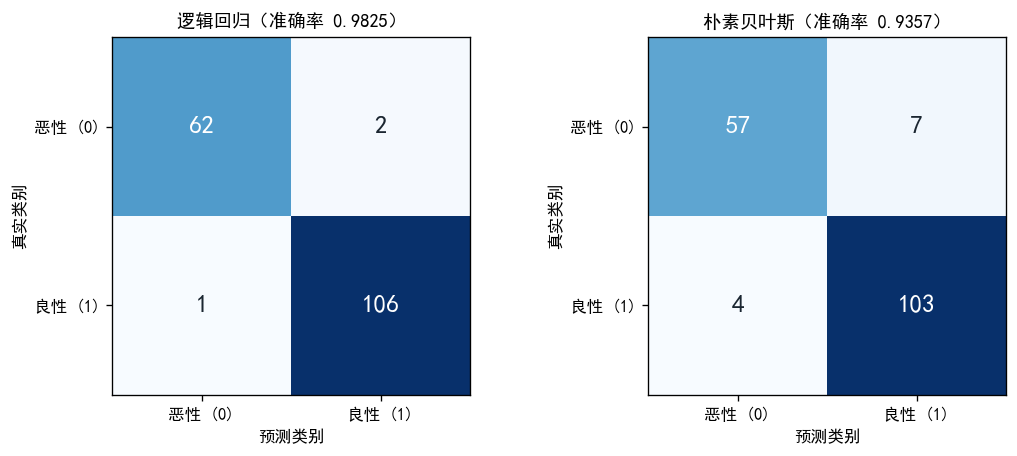

逻辑回归 混淆矩阵: [[TP=62, FN=1], [FP=2, TN=106]]（行=真实，列=预测）
朴素贝叶斯 混淆矩阵: [[TP=57, FN=4], [FP=7, TN=103]]（行=真实，列=预测）


In [22]:
# ---------- 图 5-1：两个模型的混淆矩阵 ----------
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.9))
class_labels = ["恶性 (0)", "良性 (1)"]
for ax, r in zip(axes, [RES_LR, RES_NB]):
    M = r["cm"]
    im = ax.imshow(M, cmap="Blues")
    for i in range(2):                       # 在每个格子里写数值
        for j in range(2):
            ax.text(j, i, str(M[i, j]), ha="center", va="center", fontsize=15,
                    color="white" if M[i, j] > M.max() * 0.55 else "#1B2631")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(class_labels); ax.set_yticklabels(class_labels)
    ax.set_xlabel("预测类别"); ax.set_ylabel("真实类别")
    ax.set_title("%s（准确率 %.4f）" % (r["name"], r["acc"]), fontsize=11)
    ax.grid(False)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig_confusion.png"))
plt.show()

for r in [RES_LR, RES_NB]:
    M = r["cm"]
    print("%s 混淆矩阵: [[TP=%d, FN=%d], [FP=%d, TN=%d]]（行=真实，列=预测）"
          % (r["name"], M[0, 0], M[1, 0], M[0, 1], M[1, 1]))


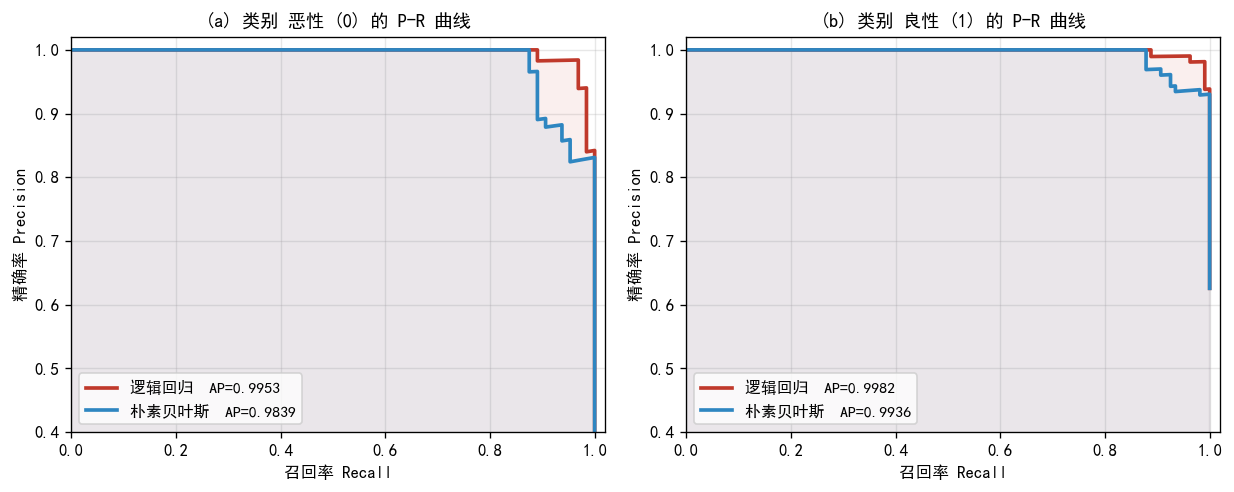

宏平均 AP：逻辑回归 0.9967，朴素贝叶斯 0.9887，高出 0.0080


In [23]:
# ---------- 图 5-2：P-R 曲线对比 ----------
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2))

for ax, c, cls_name in zip(axes, [0, 1], ["恶性 (0)", "良性 (1)"]):
    for r, color, ls in [(RES_LR, "#C0392B", "-"), (RES_NB, "#2E86C1", "-")]:
        R, P = pr_curve(y_test == c, r["proba"][:, c])
        ax.plot(R, P, color=color, lw=2.2, ls=ls,
                label="%s  AP=%.4f" % (r["name"], r["ap_per_class"][c]))
        ax.fill_between(R, P, alpha=0.08, color=color)
    ax.set_xlabel("召回率 Recall")
    ax.set_ylabel("精确率 Precision")
    ax.set_xlim(0, 1.02); ax.set_ylim(0.4, 1.02)
    ax.set_title("(a) 类别 %s 的 P-R 曲线" % cls_name if c == 0 else "(b) 类别 %s 的 P-R 曲线" % cls_name,
                 fontsize=11)
    ax.legend(loc="lower left", fontsize=9.5)

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig_pr_curves.png"))
plt.show()

print("宏平均 AP：逻辑回归 %.4f，朴素贝叶斯 %.4f，高出 %.4f"
      % (RES_LR["macro_ap"], RES_NB["macro_ap"], RES_LR["macro_ap"] - RES_NB["macro_ap"]))



### 5.2 阈值选择的影响

0.5 只是默认阈值，未必是任务的最优点。医疗场景里"漏诊恶性"的代价远大于"误报恶性"，
所以实际使用时应按需求调阈值：想要高召回率就把阈值调低。
下面给出两个模型在不同阈值下的 P / R / F1，并标出 F1 最大处的阈值。


In [24]:
# ---------- 阈值扫描 ----------
thresholds = np.arange(0.05, 0.96, 0.05)
print("表 5-4  阈值对精确率/召回率/F1 的影响（正类 = 恶性，即查出来的是不是真的恶性）")
best_th = {}
th_table = {}
for r in [RES_LR, RES_NB]:
    prob = r["proba"][:, 0]                       # 以「恶性」为正类的概率
    y_bin = (y_test == 0)
    f1s, rows_t = [], []
    for th in thresholds:
        d = binary_prf(y_bin, prob >= th)
        rows_t.append((th, d["precision"], d["recall"], d["f1"]))
        f1s.append(d["f1"])
    b = int(np.argmax(f1s))
    best_th[r["name"]] = (float(thresholds[b]), f1s[b])
    th_table[r["name"]] = [{"threshold": float(t_), "precision": p_, "recall": r_, "f1": f_}
                           for t_, p_, r_, f_ in rows_t]
    print("\n%s（F1 最大的阈值 = %.2f，此时 F1 = %.4f）" % (r["name"], thresholds[b], f1s[b]))
    print("  阈值   精确率   召回率    F1")
    for th, p_, r_, f_ in rows_t:
        mark = "  <-- 最优" if abs(th - thresholds[b]) < 1e-9 else ""
        print("  %.2f   %.4f   %.4f   %.4f%s" % (th, p_, r_, f_, mark))


表 5-4  阈值对精确率/召回率/F1 的影响（正类 = 恶性，即查出来的是不是真的恶性）

逻辑回归（F1 最大的阈值 = 0.50，此时 F1 = 0.9764）
  阈值   精确率   召回率    F1
  0.05   0.6809   1.0000   0.8101
  0.10   0.7356   1.0000   0.8477
  0.15   0.8000   1.0000   0.8889
  0.20   0.8400   0.9844   0.9065
  0.25   0.9000   0.9844   0.9403
  0.30   0.9130   0.9844   0.9474
  0.35   0.9403   0.9844   0.9618
  0.40   0.9394   0.9688   0.9538
  0.45   0.9688   0.9688   0.9688
  0.50   0.9841   0.9688   0.9764  <-- 最优
  0.55   0.9841   0.9688   0.9764
  0.60   0.9841   0.9688   0.9764
  0.65   1.0000   0.8906   0.9421
  0.70   1.0000   0.8594   0.9244
  0.75   1.0000   0.8594   0.9244
  0.80   1.0000   0.8594   0.9244
  0.85   1.0000   0.8281   0.9060
  0.90   1.0000   0.8281   0.9060
  0.95   1.0000   0.7812   0.8772

朴素贝叶斯（F1 最大的阈值 = 0.70，此时 F1 = 0.9268）
  阈值   精确率   召回率    F1
  0.05   0.8788   0.9062   0.8923
  0.10   0.8906   0.8906   0.8906
  0.15   0.9194   0.8906   0.9048
  0.20   0.9344   0.8906   0.9120
  0.25   0.9344   0.8906   0.9120
  0.30

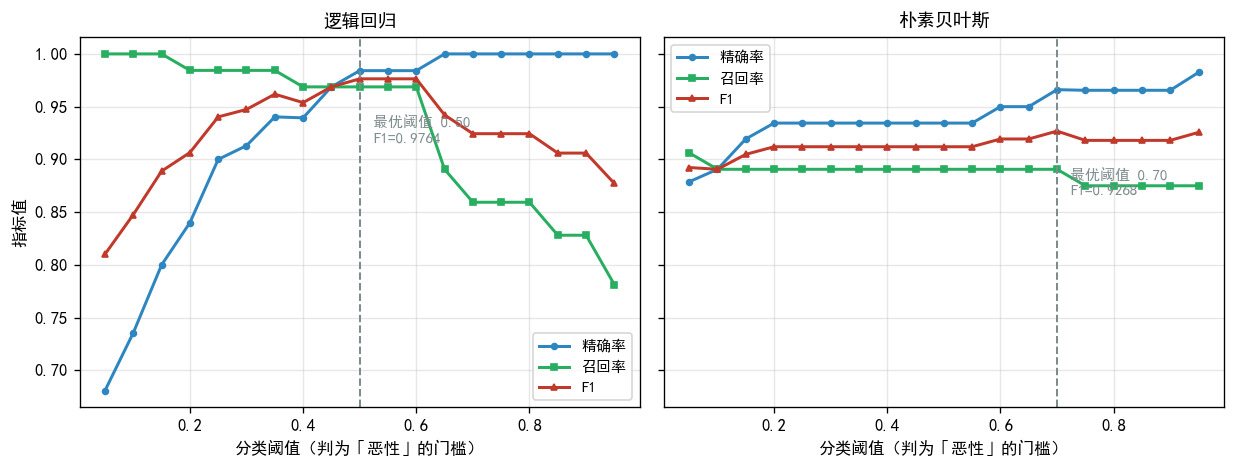

阈值降低 -> 召回率上升、精确率下降
逻辑回归的 F1 最优阈值 = 0.50，朴素贝叶斯 = 0.70
注意：逻辑回归的 F1 在 0.50~0.60 上并列最优，说明它的概率分得很开；
      朴素贝叶斯要到 0.70 才最好，反映它把良性概率整体推高了（过度自信）


In [25]:
# ---------- 图 5-3：P-R-F1 随阈值变化 ----------
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.0), sharey=True)
for ax, r in zip(axes, [RES_LR, RES_NB]):
    prob = r["proba"][:, 0]
    y_bin = (y_test == 0)
    ps, rs, fs = [], [], []
    for th in thresholds:
        d = binary_prf(y_bin, prob >= th)
        ps.append(d["precision"]); rs.append(d["recall"]); fs.append(d["f1"])
    ax.plot(thresholds, ps, "o-", ms=3.5, lw=1.8, color="#2E86C1", label="精确率")
    ax.plot(thresholds, rs, "s-", ms=3.5, lw=1.8, color="#27AE60", label="召回率")
    ax.plot(thresholds, fs, "^-", ms=3.5, lw=1.8, color="#C0392B", label="F1")
    bt, bf = best_th[r["name"]]
    ax.axvline(bt, color="#7F8C8D", ls="--", lw=1.2)
    ax.annotate("最优阈值 %.2f\nF1=%.4f" % (bt, bf), xy=(bt, bf),
                xytext=(8, -38), textcoords="offset points", fontsize=9, color="#7F8C8D")
    ax.set_xlabel("分类阈值（判为「恶性」的门槛）")
    ax.set_title(r["name"], fontsize=11)
    ax.legend(fontsize=9)
axes[0].set_ylabel("指标值")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig_threshold.png"))
plt.show()

print("阈值降低 -> 召回率上升、精确率下降")
print("逻辑回归的 F1 最优阈值 = %.2f，朴素贝叶斯 = %.2f"
      % (best_th["逻辑回归"][0], best_th["朴素贝叶斯"][0]))
print("注意：逻辑回归的 F1 在 0.50~0.60 上并列最优，说明它的概率分得很开；")
print("      朴素贝叶斯要到 0.70 才最好，反映它把良性概率整体推高了（过度自信）")



### 5.3 概率校准分析

逻辑回归直接优化对数似然，输出的是**校准过**的概率（预测为 0.9 的样本里大约有 90% 是正类）；
高斯朴素贝叶斯的概率来自"独立假设"下的密度比，通常**过度自信**（概率挤在 0 和 1 附近，
但正确率没那么高）。用可靠性曲线（reliability diagram）和 ECE 来量化。


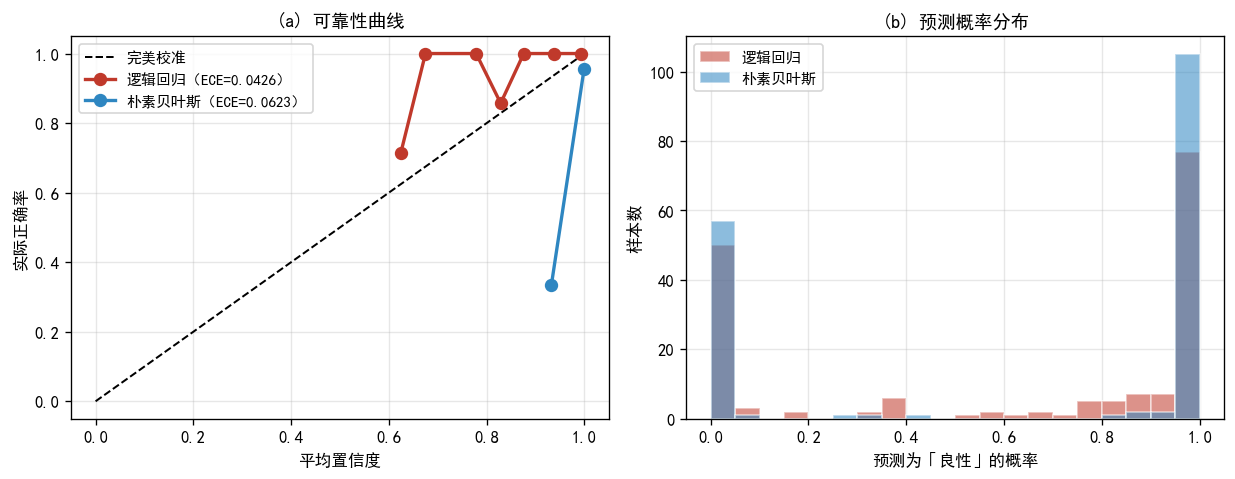

逻辑回归: ECE=0.0426，概率落在 [0,0.05)∪(0.95,1] 的样本占 74.3%
朴素贝叶斯: ECE=0.0623，概率落在 [0,0.05)∪(0.95,1] 的样本占 94.7%


In [26]:
# ---------- 图 5-4：可靠性曲线 + 预测概率分布 ----------
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.1))

# (a) 可靠性曲线
ax = axes[0]
ax.plot([0, 1], [0, 1], "k--", lw=1.2, label="完美校准")
for r, color in [(RES_LR, "#C0392B"), (RES_NB, "#2E86C1")]:
    prob = r["proba"][:, 1]
    conf = np.maximum(prob, 1 - prob)
    correct = (r["pred"] == y_test).astype(float)
    bins = np.linspace(0.5, 1.0, 11)
    xs, ys = [], []
    for i in range(10):
        lo, hi = bins[i], bins[i + 1]
        m = (conf > lo) & (conf <= hi) if i > 0 else (conf >= lo) & (conf <= hi)
        if m.sum() >= 3:
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
    ax.plot(xs, ys, "o-", color=color, lw=2, ms=7, label="%s（ECE=%.4f）" % (r["name"], r["ece"]))
ax.set_xlabel("平均置信度")
ax.set_ylabel("实际正确率")
ax.set_title("(a) 可靠性曲线", fontsize=11)
ax.legend(fontsize=9)

# (b) 概率分布直方图：越靠两端说明越"自信"
ax = axes[1]
for r, color in [(RES_LR, "#C0392B"), (RES_NB, "#2E86C1")]:
    ax.hist(r["proba"][:, 1], bins=np.linspace(0, 1, 21), alpha=0.55,
            color=color, label=r["name"], edgecolor="white")
ax.set_xlabel("预测为「良性」的概率")
ax.set_ylabel("样本数")
ax.set_title("(b) 预测概率分布", fontsize=11)
ax.legend(fontsize=9)

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig_calibration.png"))
plt.show()

for r in [RES_LR, RES_NB]:
    prob = r["proba"][:, 1]
    extreme = np.mean((prob < 0.05) | (prob > 0.95))
    print("%s: ECE=%.4f，概率落在 [0,0.05)∪(0.95,1] 的样本占 %.1f%%"
          % (r["name"], r["ece"], 100 * extreme))



### 5.4 多种子稳定性实验

一次划分的结果带有随机性（0.3 的测试集只有 171 条，错一条就是 0.6 个百分点）。
这里用 **10 个不同的随机种子**各做一次完整实验（划分 → 训练 → 评估），
给出指标的**均值 ± 标准差**，这才是可靠的比较。


In [27]:
# ---------- 10 个随机种子重复实验 ----------
seed_list = list(range(10))
seed_rows = []
for sd in seed_list:
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=sd, stratify=y)
    m_lr = LogisticRegressionGD(l2=best_lam, lr_mode="lipschitz", tol=1e-10, max_iter=30000).fit(Xa, ya)
    m_nb = GaussianNBFromScratch(var_floor=1e-9, ddof=0).fit(Xa, ya)
    for name, m in [("逻辑回归", m_lr), ("朴素贝叶斯", m_nb)]:
        proba = m.predict_proba(Xb)
        pred = m.predict(Xb)
        _, macro, _, acc, _ = prf_report(yb, pred, [0, 1])
        _, macro_ap = macro_average_precision(yb, proba, [0, 1])
        seed_rows.append({"seed": sd, "model": name, "acc": acc,
                          "macro_P": macro["precision"], "macro_R": macro["recall"],
                          "macro_F1": macro["f1"], "macro_AP": macro_ap})

seed_df = pd.DataFrame(seed_rows)
print("表 5-5  10 个随机种子下的指标（均值 ± 样本标准差）")
print("%-12s%20s%20s%20s%20s" % ("模型", "准确率", "宏精确率", "宏F1", "宏AP"))
summary = {}
for name in ["逻辑回归", "朴素贝叶斯"]:
    sub = seed_df[seed_df["model"] == name]
    cells = []
    summary[name] = {}
    for col in ["acc", "macro_P", "macro_F1", "macro_AP"]:
        mu, sd_ = sub[col].mean(), sub[col].std(ddof=1)
        summary[name][col] = (float(mu), float(sd_))
        cells.append("%.4f±%.4f" % (mu, sd_))
    print("%-12s%20s%20s%20s%20s" % (name, cells[0], cells[1], cells[2], cells[3]))


表 5-5  10 个随机种子下的指标（均值 ± 样本标准差）
模型                           准确率                宏精确率                 宏F1                 宏AP
逻辑回归               0.9725±0.0126       0.9738±0.0116       0.9704±0.0137       0.9952±0.0040
朴素贝叶斯              0.9363±0.0164       0.9357±0.0190       0.9314±0.0176       0.9833±0.0116


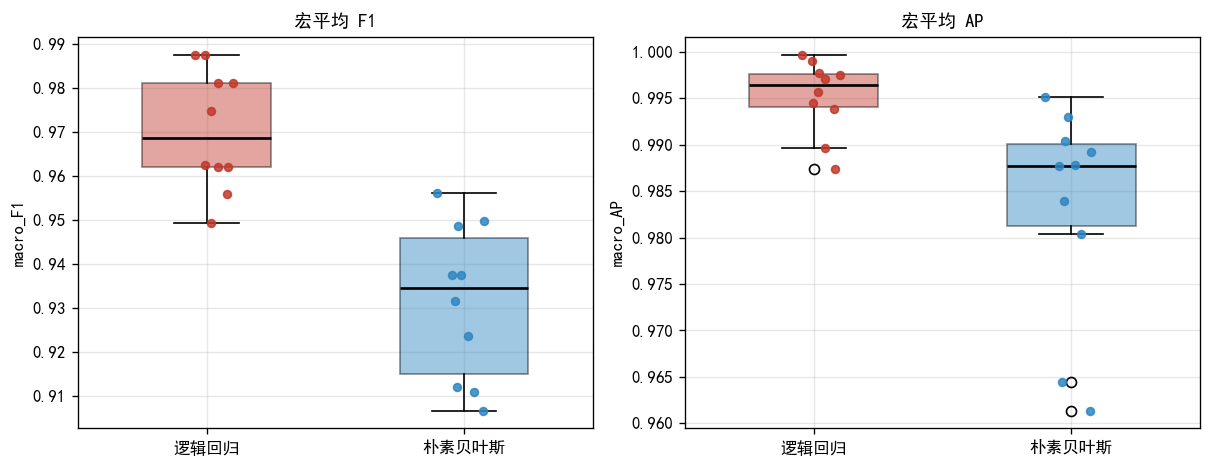

逻辑回归: 宏F1 0.9704±0.0137，宏AP 0.9952±0.0040，10 个种子中宏F1 最小 0.9494、最大 0.9876
朴素贝叶斯: 宏F1 0.9314±0.0176，宏AP 0.9833±0.0116，10 个种子中宏F1 最小 0.9066、最大 0.9562


In [28]:
# ---------- 图 5-5：10 个种子的指标分布 ----------
fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.0))
metrics = [("macro_F1", "宏平均 F1"), ("macro_AP", "宏平均 AP")]
colors = {"逻辑回归": "#C0392B", "朴素贝叶斯": "#2E86C1"}

for ax, (col, title) in zip(axes, metrics):
    data = [seed_df[seed_df["model"] == m][col].values for m in ["逻辑回归", "朴素贝叶斯"]]
    bp = ax.boxplot(data, patch_artist=True, widths=0.5,
                    tick_labels=["逻辑回归", "朴素贝叶斯"], medianprops=dict(color="black", lw=1.6))
    for patch, m in zip(bp["boxes"], ["逻辑回归", "朴素贝叶斯"]):
        patch.set_facecolor(colors[m]); patch.set_alpha(0.45)
    for i, d in enumerate(data):                    # 叠加原始散点
        ax.scatter(np.random.RandomState(i).normal(i + 1, 0.045, len(d)), d,
                   s=22, color=colors[["逻辑回归", "朴素贝叶斯"][i]], zorder=3, alpha=0.85)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel(col)

fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig_seed_stability.png"))
plt.show()

for m in ["逻辑回归", "朴素贝叶斯"]:
    sub = seed_df[seed_df["model"] == m]
    print("%s: 宏F1 %.4f±%.4f，宏AP %.4f±%.4f，10 个种子中宏F1 最小 %.4f、最大 %.4f"
          % (m, sub["macro_F1"].mean(), sub["macro_F1"].std(ddof=1),
             sub["macro_AP"].mean(), sub["macro_AP"].std(ddof=1),
             sub["macro_F1"].min(), sub["macro_F1"].max()))



### 5.5 从模型参数看两种方法的差异

逻辑回归学到的权重可以直接比较（特征已标准化，权重绝对值大小表示该特征的贡献），
高斯朴素贝叶斯学的是"两类各自的高斯中心"，二者之差可以类比为"判别方向"。


逻辑回归的截距 b = 0.4364

表 5-6  逻辑回归权重绝对值最大的 10 个特征（已标准化，正=推向良性）
特征                                权重         恶性组均值         良性组均值
worst texture                -0.7535       29.4819       23.6463
worst concave points         -0.6710        0.1853        0.0726
worst radius                 -0.6494       21.1803       13.3576
worst area                   -0.6083     1424.5986      557.1148
worst perimeter              -0.5635      141.7139       86.8007
worst symmetry               -0.5561        0.3303        0.2708
worst smoothness             -0.5312        0.1451        0.1246
area error                   -0.5016       66.8486       21.2644
worst concavity              -0.4800        0.4735        0.1634
mean concave points          -0.4783        0.0875        0.0247

权重符号统计：正权重 7 个，负权重 23 个
权重绝对值最大 0.7535，最小 0.0851


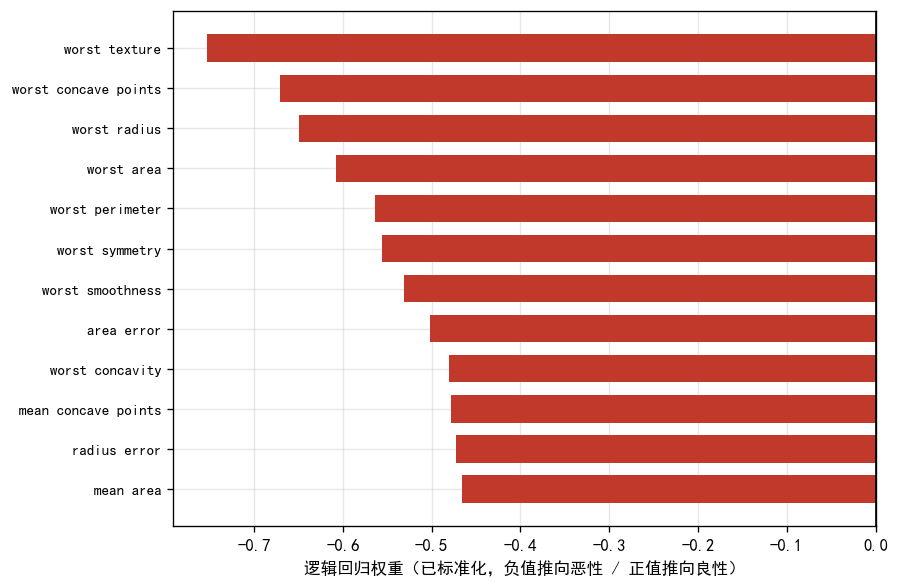

In [29]:
# ---------- 逻辑回归权重：标准化后可直接比较大小 ----------
coef = LR_FINAL.w_[:-1]                      # 去掉偏置
intercept = LR_FINAL.w_[-1]
order = np.argsort(-np.abs(coef))            # 按绝对值降序

print("逻辑回归的截距 b = %.4f" % intercept)
print("\n表 5-6  逻辑回归权重绝对值最大的 10 个特征（已标准化，正=推向良性）")
print("%-24s%12s%14s%14s" % ("特征", "权重", "恶性组均值", "良性组均值"))
for j in order[:10]:
    print("%-24s%12.4f%14.4f%14.4f" % (feature_names[j], coef[j],
                                       GNB.mean_[0, j], GNB.mean_[1, j]))

print("\n权重符号统计：正权重 %d 个，负权重 %d 个"
      % (int(np.sum(coef > 0)), int(np.sum(coef < 0))))
print("权重绝对值最大 %.4f，最小 %.4f" % (np.abs(coef).max(), np.abs(coef).min()))

# ---------- 图 5-6：权重条形图 ----------
fig, ax = plt.subplots(figsize=(7.6, 5.0))
top = order[:12]
colors_bar = ["#C0392B" if coef[j] < 0 else "#27AE60" for j in top]
ax.barh(np.arange(len(top)), coef[top][::-1], color=colors_bar[::-1], height=0.68)
ax.set_yticks(np.arange(len(top)))
ax.set_yticklabels([feature_names[j] for j in top][::-1], fontsize=9)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("逻辑回归权重（已标准化，负值推向恶性 / 正值推向良性）")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig_lr_coef.png"))
plt.show()



### 5.6 训练集规模的影响（学习曲线）

前面所有实验都用了 398 条训练样本。一个自然的问题是：**如果样本更少，朴素贝叶斯会不会反超？**
从偏差-方差的角度看，朴素贝叶斯参数少、方差低，通常在小样本下更有优势。
下面把训练集按类别分层随机抽取 10%、20%、30%、50%、70%、100%，固定测试集不变，
看两种方法的宏 F1 如何变化。


In [30]:
# ---------- 学习曲线：训练集规模 vs 宏 F1 ----------
fracs = [0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
lc_rows = []
sub_rng = np.random.RandomState(0)               # 控制子集抽取的随机性
for frac in fracs:
    idx = []
    for c in [0, 1]:                             # 按类别分层抽取，保证子集类别比例不变
        idc = np.where(y_train == c)[0]
        sub_rng.shuffle(idc)
        idx.append(idc[:int(round(len(idc) * frac))])
    idx = np.concatenate(idx)
    Xa, ya = X_train[idx], y_train[idx]          # 子训练集（测试集始终不变）
    m_lr = LogisticRegressionGD(l2=best_lam, lr_mode="lipschitz", tol=1e-10, max_iter=30000).fit(Xa, ya)
    m_nb = GaussianNBFromScratch(var_floor=1e-9, ddof=0).fit(Xa, ya)
    row = {"frac": frac, "n_train": int(len(idx))}
    for nm, m in [("LR", m_lr), ("GNB", m_nb)]:
        _, mac, _, acc, _ = prf_report(y_test, m.predict(X_test), [0, 1])
        aps, macro_ap = macro_average_precision(y_test, m.predict_proba(X_test), [0, 1])
        row[nm + "_f1"] = mac["f1"]
        row[nm + "_ap"] = macro_ap
        row[nm + "_acc"] = acc
    lc_rows.append(row)

print("表 5-6  训练集规模对测试集宏 F1 的影响（测试集固定，171 条）")
print("%10s%10s%12s%12s%12s" % ("训练比例", "训练样本", "逻辑回归 F1", "朴素贝叶斯 F1", "F1 差距"))
for row in lc_rows:
    print("%9.0f%%%10d%12.4f%12.4f%+12.4f"
          % (100 * row["frac"], row["n_train"], row["LR_f1"], row["GNB_f1"], row["LR_f1"] - row["GNB_f1"]))


表 5-6  训练集规模对测试集宏 F1 的影响（测试集固定，171 条）
      训练比例      训练样本     逻辑回归 F1    朴素贝叶斯 F1       F1 差距
       10%        40      0.9383      0.9180     +0.0203
       20%        80      0.9750      0.9440     +0.0310
       30%       119      0.9623      0.9367     +0.0256
       50%       199      0.9812      0.9241     +0.0571
       70%       279      0.9812      0.9186     +0.0626
      100%       398      0.9812      0.9307     +0.0506


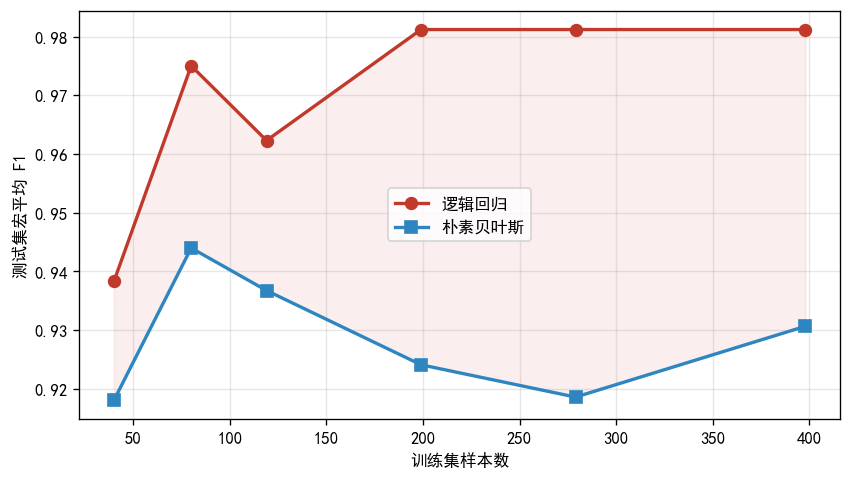

样本最少（40 条）时两者差距最小（0.0203）；样本增多后差距反而拉大到 0.0506
朴素贝叶斯的宏 F1 基本停留在 0.92~0.94，逻辑回归则随样本增加持续改善


In [31]:
# ---------- 图 5-6：学习曲线 ----------
fig, ax = plt.subplots(figsize=(7.2, 4.1))
ns = [r["n_train"] for r in lc_rows]
ax.plot(ns, [r["LR_f1"] for r in lc_rows], "o-", color="#C0392B", lw=2, ms=7, label="逻辑回归")
ax.plot(ns, [r["GNB_f1"] for r in lc_rows], "s-", color="#2E86C1", lw=2, ms=7, label="朴素贝叶斯")
ax.fill_between(ns, [r["GNB_f1"] for r in lc_rows], [r["LR_f1"] for r in lc_rows],
                color="#C0392B", alpha=0.08)
ax.set_xlabel("训练集样本数")
ax.set_ylabel("测试集宏平均 F1")
ax.legend(fontsize=10)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "fig_learning_curve.png"))
plt.show()

print("样本最少（%d 条）时两者差距最小（%.4f）；样本增多后差距反而拉大到 %.4f"
      % (lc_rows[0]["n_train"], lc_rows[0]["LR_f1"] - lc_rows[0]["GNB_f1"],
         lc_rows[-1]["LR_f1"] - lc_rows[-1]["GNB_f1"]))
print("朴素贝叶斯的宏 F1 基本停留在 %.2f~%.2f，逻辑回归则随样本增加持续改善"
      % (min(r["GNB_f1"] for r in lc_rows), max(r["GNB_f1"] for r in lc_rows)))



### 5.7 两种方法计算代价的对比

- 逻辑回归：**迭代**求解，每一轮都要遍历全部训练样本和全部特征，
  计算量约为 `O(T \cdot N \cdot d)`（T 为迭代轮数）。
- 高斯朴素贝叶斯：**闭式估计**，只需把训练集扫描一遍，
  计算量约为 `O(N \cdot d)`，没有迭代。

下面实测训练耗时（同一台机器，单线程）。


In [32]:
import time

# 每种方法重复 5 次取平均，减少计时噪声
def timeit(fn, repeat=5):
    ts = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        fn()
        ts.append(time.perf_counter() - t0)
    return float(np.mean(ts)), float(np.std(ts, ddof=1))

t_lr, s_lr = timeit(lambda: LogisticRegressionGD(l2=best_lam, lr_mode="lipschitz",
                                                 tol=1e-10, max_iter=30000).fit(X_train, y_train))
t_nb, s_nb = timeit(lambda: GaussianNBFromScratch(var_floor=1e-9).fit(X_train, y_train))

print("表 5-7  训练耗时对比（重复 5 次）")
print("%-14s%16s%14s%18s" % ("模型", "平均耗时/ms", "标准差/ms", "迭代轮数"))
print("%-14s%16.2f%14.2f%18d" % ("逻辑回归", t_lr * 1000, s_lr * 1000, LR_FINAL.n_iter_))
print("%-14s%16.2f%14.2f%18s" % ("朴素贝叶斯", t_nb * 1000, s_nb * 1000, "0（闭式）"))
print("\n逻辑回归训练耗时是朴素贝叶斯的 %.1f 倍" % (t_lr / t_nb))


表 5-7  训练耗时对比（重复 5 次）
模型                     平均耗时/ms        标准差/ms              迭代轮数
逻辑回归                     95.21          6.62              1629
朴素贝叶斯                     0.13          0.03             0（闭式）

逻辑回归训练耗时是朴素贝叶斯的 710.3 倍



## 6. 结论与结果导出

最后把报告需要用到的全部数字打包成 `results.json`，并打印结论摘要。


In [33]:
# ---------- 收集全部结果，导出 JSON 供报告写作使用 ----------
def f(x):
    """numpy 标量 -> Python 原生 float，保证 JSON 可序列化"""
    return float(x)


results = {
    "meta": {
        "student_id": "XXXXXXXXXX", "name": "XXX", "group": "B",
        "date": "2026-10-25", "seed": SEED,
        "n_samples": int(X.shape[0]), "n_features": int(X.shape[1]),
        "class_counts": {"malignant(0)": int(np.sum(y == 0)), "benign(1)": int(np.sum(y == 1))},
        "split": {"train": int(len(y_train)), "test": int(len(y_test)), "test_size": 0.3},
        "versions": {"python": sys.version.split()[0], "numpy": np.__version__,
                     "sklearn": sklearn.__version__, "matplotlib": matplotlib.__version__},
        "n_strong_corr_pairs_0.9": int(n_strong),
        "std_ratio_max_min": f(stats["std"].max() / stats["std"].min()),
    },
    "lr": {
        "best_lambda": f(best_lam), "eta": f(LR_FINAL.eta_), "L": f(LR_FINAL.L_),
        "n_iter": int(LR_FINAL.n_iter_), "stop_reason": LR_FINAL.stop_reason_,
        "loss_start": f(LR_FINAL.loss_hist_[0]), "loss_end": f(LR_FINAL.loss_hist_[-1]),
        "grad_inf": f(LR_FINAL.grad_norm_hist_[-1]),
        "w_norm": f(np.linalg.norm(LR_FINAL.w_[:-1])), "intercept": f(LR_FINAL.w_[-1]),
        "train_time_ms": f(t_lr * 1000), "train_time_std_ms": f(s_lr * 1000),
        "cv_table": [{k: (f(v) if isinstance(v, (int, float, np.floating)) and not isinstance(v, bool) else v)
                      for k, v in row.items()} for row in rows],
    },
    "gnb": {
        "var_floor": 1e-9, "min_var": f(GNB.var_.min()), "max_var": f(GNB.var_.max()),
        "priors": [f(GNB.prior_[0]), f(GNB.prior_[1])],
        "train_time_ms": f(t_nb * 1000), "train_time_std_ms": f(s_nb * 1000),
        "scale_inv_max_abs_diff": f(np.max(np.abs(p_raw - p_std))),
    },
    "eval": {
        "lr": {k: v for k, v in RES_LR.items() if k not in ("pred", "proba")},
        "gnb": {k: v for k, v in RES_NB.items() if k not in ("pred", "proba")},
        "best_threshold": {k: {"threshold": f(v[0]), "f1": f(v[1])} for k, v in best_th.items()},
        "seed_summary": summary,
        "seed_rows": seed_rows,
        "learning_curve": lc_rows,
        "threshold_table": th_table,
        "standardization": {
            "L_std": f(lr_std.L_), "eta_std": f(lr_std.eta_),
            "cond_std": f(cond_std), "loss_std": f(lr_std.loss_hist_[-1]),
            "acc_std": f(np.mean(lr_std.predict(X_test) == y_test)),
            "iters_std": int(lr_std.n_iter_), "conv_std": bool(lr_std.converged_),
            "L_raw": f(lr_raw.L_), "eta_raw": f(lr_raw.eta_),
            "cond_raw": f(cond_raw), "loss_raw": f(lr_raw.loss_hist_[-1]),
            "acc_raw": f(np.mean(lr_raw.predict(X_test) == y_test)),
            "iters_raw": int(lr_raw.n_iter_), "conv_raw": bool(lr_raw.converged_),
            "eta_ratio": f(lr_std.eta_ / lr_raw.eta_),
            "cond_ratio": f(cond_raw / cond_std),
        },
        "coef_top": [{"name": str(feature_names[j]), "weight": f(coef[j]),
                      "mean0": f(GNB.mean_[0, j]), "mean1": f(GNB.mean_[1, j])}
                     for j in order[:10]],
        "coef_pos": int(np.sum(coef > 0)), "coef_neg": int(np.sum(coef < 0)),
        "coef_absmax": f(np.abs(coef).max()), "coef_absmin": f(np.abs(coef).min()),
        "lambda_table": lambda_table.to_dict(orient="records"),
    },
}

def to_jsonable(obj):
    """递归地把 numpy 标量/数组转换成 JSON 原生类型"""
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    return obj


with open("results.json", "w", encoding="utf-8") as fp:
    json.dump(to_jsonable(results), fp, ensure_ascii=False, indent=2)
print("结果已写入 results.json（%d 字节）" % os.path.getsize("results.json"))

# ---------- 结论摘要 ----------
print("\n" + "=" * 66)
print("结论摘要")
print("=" * 66)
print("1) 逻辑回归：宏平均 AP = %.4f，宏平均 F1 = %.4f，准确率 = %.4f，AUC = %.4f"
      % (RES_LR["macro_ap"], RES_LR["macro"]["f1"], RES_LR["acc"], RES_LR["auc"]))
print("2) 朴素贝叶斯：宏平均 AP = %.4f，宏平均 F1 = %.4f，准确率 = %.4f，AUC = %.4f"
      % (RES_NB["macro_ap"], RES_NB["macro"]["f1"], RES_NB["acc"], RES_NB["auc"]))
print("3) 宏平均 AP 差距 = %.4f，宏 F1 差距 = %.4f，均为逻辑回归更高"
      % (RES_LR["macro_ap"] - RES_NB["macro_ap"], RES_LR["macro"]["f1"] - RES_NB["macro"]["f1"]))
print("4) 10 个种子上：逻辑回归宏F1 %.4f±%.4f，朴素贝叶斯 %.4f±%.4f"
      % (*summary["逻辑回归"]["macro_F1"], *summary["朴素贝叶斯"]["macro_F1"]))
print("5) 校准：逻辑回归 ECE = %.4f 优于朴素贝叶斯 ECE = %.4f"
      % (RES_LR["ece"], RES_NB["ece"]))
print("6) 代价：逻辑回归训练 %.1f ms（%d 轮迭代），朴素贝叶斯 %.1f ms（闭式、0 轮迭代）"
      % (t_lr * 1000, LR_FINAL.n_iter_, t_nb * 1000))
print("7) 特征标准化：逻辑回归必须做（步长差 %.0f 倍、条件数差 %.0e 倍）；朴素贝叶斯严格不变"
      % (lr_std.eta_ / lr_raw.eta_, cond_raw / cond_std))
print("=" * 66)


结果已写入 results.json（25748 字节）

结论摘要
1) 逻辑回归：宏平均 AP = 0.9967，宏平均 F1 = 0.9812，准确率 = 0.9825，AUC = 0.9969
2) 朴素贝叶斯：宏平均 AP = 0.9887，宏平均 F1 = 0.9307，准确率 = 0.9357，AUC = 0.9892
3) 宏平均 AP 差距 = 0.0080，宏 F1 差距 = 0.0506，均为逻辑回归更高
4) 10 个种子上：逻辑回归宏F1 0.9704±0.0137，朴素贝叶斯 0.9314±0.0176
5) 校准：逻辑回归 ECE = 0.0426 优于朴素贝叶斯 ECE = 0.0623
6) 代价：逻辑回归训练 95.2 ms（1629 轮迭代），朴素贝叶斯 0.1 ms（闭式、0 轮迭代）
7) 特征标准化：逻辑回归必须做（步长差 121168 倍、条件数差 2e+07 倍）；朴素贝叶斯严格不变
